# Safeguarded DQAOA-on-QUBO binary block for 3-block ADMM UC

This notebook has: package cell, ADMM cell, varied UC example, and mode configs.

In [1]:
from __future__ import annotations

import math
import time
import threading
from concurrent.futures import ThreadPoolExecutor, as_completed
from dataclasses import dataclass
from typing import Dict, Tuple, List, Optional, Any, Callable

import numpy as np

# =============================================================================
# Optional imports
# =============================================================================
HAVE_QISKIT = True
QISKIT_IMPORT_ERROR = None
try:
    from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
    from qiskit.circuit import ParameterVector
    from qiskit_aer import AerSimulator
except Exception as e:
    HAVE_QISKIT = False
    QISKIT_IMPORT_ERROR = e

HAVE_DOCPLEX = True
DOCPLEX_IMPORT_ERROR = None
try:
    from docplex.mp.model import Model
except Exception as e:
    HAVE_DOCPLEX = False
    DOCPLEX_IMPORT_ERROR = e

HAVE_MATPLOTLIB = True
MATPLOTLIB_IMPORT_ERROR = None
try:
    import matplotlib.pyplot as plt
except Exception as e:
    HAVE_MATPLOTLIB = False
    MATPLOTLIB_IMPORT_ERROR = e


# =============================================================================
# Data containers
# =============================================================================
@dataclass
class QUBOInstance:
    name: str
    n: int
    c0: float
    linear: np.ndarray
    quadratic: Dict[Tuple[int, int], float]   # only i<j


@dataclass
class TrainConfig:
    shots_train: int = 256
    avg_k: int = 1
    seed_trans: int = 1234
    seed_base: int = 7
    optimization_level: int = 1
    sim_method: str = "automatic"
    batch_evaluations: bool = True


@dataclass
class AdamConfig:
    iters: int = 8
    lr: float = 0.08
    beta1: float = 0.9
    beta2: float = 0.999
    eps: float = 1e-8
    fd_eps0: float = 0.12
    seed: int = 0
    spsa_alpha: float = 0.602
    spsa_gamma: float = 0.101
    spsa_A: float = 0.0
    eval_at_each_iter: bool = True

@dataclass
class QuboObjectiveConfig:
    """
    Training objective is intentionally pure mean_cost.
    This config is kept only for compatibility and reporting settings.
    """
    objective_name: str = "mean_cost"
    delta_close_cost: float = 0.0


@dataclass
class MultiStartConfig:
    num_random_starts: int = 4
    warm_start_perturbations: int = 1
    warm_start_sigma: float = 0.10
    add_plain_warm_start: bool = True
    keep_top_k_per_depth: int = 1
    select_by_exact_when_available: bool = False
    parallel_restarts: int = 1


@dataclass
class AnalysisConfig:
    elite_top_k: int = 10
    certificate_tol: float = 1e-9

@dataclass
class ConvergenceConfig:
    stable_window: int = 3
    obj_tol: float = 1e-3
    mean_cost_tol: float = 1e-3
    p_best_tol: float = 1e-3
    p_close_tol: float = 1e-3
    gap_tol: float = 1e-3


# =============================================================================
# Generic utilities
# =============================================================================
def clip_angles(x: np.ndarray) -> np.ndarray:
    return np.mod(np.asarray(x, dtype=float), np.pi)


def bitstring_from_int(x: int, n: int) -> str:
    return format(x, f"0{n}b")


def invert_endianness(bs: str) -> str:
    return bs.replace(" ", "")[::-1]


def require_qiskit():
    if not HAVE_QISKIT:
        raise ImportError(
            "This mode requires qiskit and qiskit-aer, but they could not be imported.\n"
            f"Original import error: {QISKIT_IMPORT_ERROR}"
        )


def require_docplex():
    if not HAVE_DOCPLEX:
        raise ImportError(
            "This mode requires docplex (and a local CPLEX installation), but docplex "
            f"could not be imported.\nOriginal import error: {DOCPLEX_IMPORT_ERROR}"
        )


def require_matplotlib():
    if not HAVE_MATPLOTLIB:
        raise ImportError(
            "This plotting function requires matplotlib, but it could not be imported.\n"
            f"Original import error: {MATPLOTLIB_IMPORT_ERROR}"
        )


def _to_py_scalar(x):
    if isinstance(x, (np.floating,)):
        return float(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    return x


def _to_py_float_list(arr) -> List[float]:
    return [float(v) for v in np.asarray(arr, dtype=float).ravel().tolist()]


def summarize_result(res: Dict[str, Any]) -> Dict[str, Any]:
    out = {
        "mode": res.get("mode"),
        "status": res.get("status"),
        "best_bitstring": res.get("best_bitstring"),
        "best_cost": _to_py_scalar(res.get("best_cost")),
        "incumbent_bitstring": res.get("incumbent_bitstring", res.get("best_bitstring")),
        "incumbent_cost": _to_py_scalar(res.get("incumbent_cost", res.get("best_cost"))),
        "mean_cost": _to_py_scalar(res.get("mean_cost")),
        "runtime_to_solution_seconds": _to_py_scalar(res.get("runtime_to_solution_seconds")),
        "remote_cx_count": _to_py_scalar(res.get("remote_cx_count")),
        "cross_qpu_terms": _to_py_scalar(res.get("cross_qpu_terms")),
        "final_objective_value": _to_py_scalar(res.get("final_objective_value")),
        "final_p_best_observed": _to_py_scalar(res.get("final_p_best_observed")),
        "final_p_close_cost": _to_py_scalar(res.get("final_p_close_cost")),
        "final_p_exact_bitstring": _to_py_scalar(res.get("final_p_exact_bitstring")),
        "final_p_exact_cost": _to_py_scalar(res.get("final_p_exact_cost")),
        "final_p_incumbent_bitstring": _to_py_scalar(res.get("final_p_incumbent_bitstring", res.get("final_p_best_observed"))),
        "final_p_incumbent_cost": _to_py_scalar(res.get("final_p_incumbent_cost", res.get("final_p_best_observed"))),
        "elite_top_k": _to_py_scalar(res.get("elite_top_k")),
        "elite_mass_top_k": _to_py_scalar(res.get("elite_mass_top_k")),
        "elite_mean_cost_top_k": _to_py_scalar(res.get("elite_mean_cost_top_k")),
        "num_unique_sampled": _to_py_scalar(res.get("num_unique_sampled")),
        "distribution_gap": _to_py_scalar(res.get("distribution_gap")),
        "practical_converged": res.get("practical_converged"),
        "stable_over_window": res.get("stable_over_window"),
        "exact_optimum_cost": _to_py_scalar(res.get("exact_optimum_cost")),
        "optimality_gap_to_exact": _to_py_scalar(res.get("optimality_gap_to_exact")),
        "cost_match_exact": res.get("cost_match_exact"),
        "bitstring_match_exact": res.get("bitstring_match_exact"),
        "certificate_lower_bound": _to_py_scalar(res.get("certificate_lower_bound")),
        "certificate_gap": _to_py_scalar(res.get("certificate_gap")),
        "certified_optimal": res.get("certified_optimal"),
        "restart_consensus_cost": _to_py_scalar(res.get("restart_consensus_cost")),
        "restart_consensus_bitstring": _to_py_scalar(res.get("restart_consensus_bitstring")),
        "mode_consensus_cost": _to_py_scalar(res.get("mode_consensus_cost")),
        "mode_consensus_bitstring": _to_py_scalar(res.get("mode_consensus_bitstring")),
    }
    if "p" in res:
        out["p"] = _to_py_scalar(res.get("p"))
    if "angles" in res:
        out["angles"] = [float(v) for v in res.get("angles", [])]
    if "gammas" in res:
        out["gammas"] = [float(v) for v in res.get("gammas", [])]
    if "betas" in res:
        out["betas"] = [float(v) for v in res.get("betas", [])]
    if "details" in res and isinstance(res["details"], dict):
        out["details"] = res["details"]
    return out


def print_result_summary(res: Dict[str, Any]):
    s = summarize_result(res)
    print("\n================ QUBO RESULT SUMMARY ================")
    print(f"mode                      = {s.get('mode')}")
    print(f"status                    = {s.get('status')}")
    if 'p' in s:
        print(f"p                         = {s.get('p')}")
    print(f"best_bitstring            = {s.get('best_bitstring')}")
    print(f"best_cost                 = {s.get('best_cost')}")
    print(f"incumbent_bitstring       = {s.get('incumbent_bitstring')}")
    print(f"incumbent_cost            = {s.get('incumbent_cost')}")
    print(f"mean_cost                 = {s.get('mean_cost')}")
    print(f"final_objective_value     = {s.get('final_objective_value')}")
    print(f"final_p_best_observed     = {s.get('final_p_best_observed')}")
    print(f"final_p_close_cost        = {s.get('final_p_close_cost')}")
    print(f"final_p_exact_bitstring   = {s.get('final_p_exact_bitstring')}")
    print(f"final_p_exact_cost        = {s.get('final_p_exact_cost')}")
    print(f"final_p_inc_bitstring     = {s.get('final_p_incumbent_bitstring')}")
    print(f"final_p_inc_cost          = {s.get('final_p_incumbent_cost')}")
    print(f"elite_top_k               = {s.get('elite_top_k')}")
    print(f"elite_mass_top_k          = {s.get('elite_mass_top_k')}")
    print(f"elite_mean_cost_top_k     = {s.get('elite_mean_cost_top_k')}")
    print(f"num_unique_sampled        = {s.get('num_unique_sampled')}")
    print(f"distribution_gap          = {s.get('distribution_gap')}")
    print(f"restart_consensus_cost    = {s.get('restart_consensus_cost')}")
    print(f"restart_consensus_bs      = {s.get('restart_consensus_bitstring')}")
    print(f"mode_consensus_cost       = {s.get('mode_consensus_cost')}")
    print(f"mode_consensus_bs         = {s.get('mode_consensus_bitstring')}")
    print(f"practical_converged       = {s.get('practical_converged')}")
    print(f"stable_over_window        = {s.get('stable_over_window')}")
    print(f"exact_optimum_cost        = {s.get('exact_optimum_cost')}")
    print(f"optimality_gap_to_exact   = {s.get('optimality_gap_to_exact')}")
    print(f"cost_match_exact          = {s.get('cost_match_exact')}")
    print(f"bitstring_match_exact     = {s.get('bitstring_match_exact')}")
    print(f"certificate_lower_bound   = {s.get('certificate_lower_bound')}")
    print(f"certificate_gap           = {s.get('certificate_gap')}")
    print(f"certified_optimal         = {s.get('certified_optimal')}")
    print(f"runtime_to_solution_s     = {s.get('runtime_to_solution_seconds')}")
    print(f"remote_cx_count           = {s.get('remote_cx_count')}")
    print(f"cross_qpu_terms           = {s.get('cross_qpu_terms')}")
    if "angles" in s:
        print(f"angles                    = {s.get('angles')}")
    if "gammas" in s:
        print(f"gammas                    = {s.get('gammas')}")
    if "betas" in s:
        print(f"betas                     = {s.get('betas')}")
    if "details" in s:
        print(f"details                   = {s.get('details')}")
    print("=====================================================\n")


# =============================================================================
# QUBO canonicalization / evaluation
# =============================================================================
def canonicalize_qubo_from_dense(
    H: np.ndarray,
    f: Optional[np.ndarray] = None,
    c0: float = 0.0,
    name: str = "generic_qubo",
    tol: float = 1e-14,
) -> QUBOInstance:
    H = np.asarray(H, dtype=float)
    if H.ndim != 2 or H.shape[0] != H.shape[1]:
        raise ValueError("H must be a square matrix.")
    n = H.shape[0]
    if f is None:
        f = np.zeros(n, dtype=float)
    else:
        f = np.asarray(f, dtype=float).reshape(-1)
        if len(f) != n:
            raise ValueError("len(f) must equal H.shape[0].")
    linear = f.copy()
    quadratic: Dict[Tuple[int, int], float] = {}
    linear += np.diag(H)
    for i in range(n):
        for j in range(i + 1, n):
            bij = H[i, j] + H[j, i]
            if abs(bij) > tol:
                quadratic[(i, j)] = float(bij)
    return QUBOInstance(
        name=name,
        n=n,
        c0=float(c0),
        linear=linear.astype(float),
        quadratic=quadratic,
    )


def qubo_value_from_bitstring(bs_qubit_order: str, instance: QUBOInstance) -> float:
    z = np.array([int(ch) for ch in bs_qubit_order], dtype=float)
    val = instance.c0
    val += float(np.dot(instance.linear, z))
    for (i, j), bij in instance.quadratic.items():
        val += bij * z[i] * z[j]
    return float(val)


# =============================================================================
# Exact classical references
# =============================================================================
def solve_qubo_bruteforce(instance: QUBOInstance) -> Dict[str, Any]:
    t0 = time.perf_counter()
    best_cost = float("inf")
    best_bs = None
    all_costs: Dict[str, float] = {}
    for x in range(2 ** instance.n):
        bs = bitstring_from_int(x, instance.n)
        val = qubo_value_from_bitstring(bs, instance)
        all_costs[bs] = float(val)
        if val < best_cost:
            best_cost = val
            best_bs = bs
    optimal_bitstrings = sorted([bs for bs, cost in all_costs.items() if abs(cost - best_cost) <= 1e-12])
    elapsed = time.perf_counter() - t0
    return {
        "mode": "bruteforce",
        "status": "optimal",
        "best_cost": float(best_cost),
        "best_bitstring": str(best_bs),
        "optimal_bitstrings": optimal_bitstrings,
        "optimal_degeneracy": len(optimal_bitstrings),
        "mean_cost": None,
        "runtime_to_solution_seconds": float(elapsed),
        "remote_cx_count": 0,
        "cross_qpu_terms": 0,
        "details": {},
    }


def solve_qubo_miqp_cplex(instance: QUBOInstance, time_limit: Optional[float] = None) -> Dict[str, Any]:
    require_docplex()
    t0 = time.perf_counter()
    mdl = Model(name=f"qubo_{instance.name}")
    z = mdl.binary_var_list(instance.n, name="z")
    obj = instance.c0
    for i in range(instance.n):
        obj += instance.linear[i] * z[i]
    for (i, j), bij in instance.quadratic.items():
        obj += bij * z[i] * z[j]
    mdl.minimize(obj)
    if time_limit is not None:
        mdl.parameters.timelimit = float(time_limit)
    sol = mdl.solve(log_output=False)
    elapsed = time.perf_counter() - t0
    if sol is None:
        return {
            "mode": "miqp_cplex",
            "status": "no_solution",
            "best_cost": None,
            "best_bitstring": None,
            "mean_cost": None,
            "runtime_to_solution_seconds": float(elapsed),
            "remote_cx_count": 0,
            "cross_qpu_terms": 0,
            "details": {"solver_status": str(mdl.solve_details.status)},
        }
    best_z = np.array([int(round(sol.get_value(v))) for v in z], dtype=int)
    best_bs = "".join(str(int(v)) for v in best_z)
    best_cost = qubo_value_from_bitstring(best_bs, instance)
    return {
        "mode": "miqp_cplex",
        "status": "optimal_or_best_found",
        "best_cost": float(best_cost),
        "best_bitstring": best_bs,
        "mean_cost": None,
        "runtime_to_solution_seconds": float(elapsed),
        "remote_cx_count": 0,
        "cross_qpu_terms": 0,
        "details": {
            "solver_status": str(mdl.solve_details.status),
            "objective_from_docplex": float(sol.objective_value),
        },
    }


# =============================================================================
# Allocation helpers
# =============================================================================
def make_balanced_capacities(n: int, num_qpus: int) -> List[int]:
    if num_qpus < 1:
        raise ValueError("num_qpus must be >= 1")
    if num_qpus > n:
        raise ValueError("num_qpus cannot exceed n")
    base = n // num_qpus
    rem = n % num_qpus
    return [base + (1 if i < rem else 0) for i in range(num_qpus)]


def validate_allocation(
    n: int,
    num_qpus: int,
    capacities: List[int],
    allocation: Dict[int, Tuple[int, int]],
    min_used_qpus: int = 1,
):
    if set(allocation.keys()) != set(range(n)):
        raise ValueError("Allocation must contain every node exactly once.")
    seen_slots = set()
    used_qpus = set()
    for node in range(n):
        q, local = allocation[node]
        if not (0 <= q < num_qpus):
            raise ValueError(f"Node {node} assigned to invalid QPU {q}.")
        if not (0 <= local < capacities[q]):
            raise ValueError(f"Invalid local slot for node {node} on QPU {q}.")
        if (q, local) in seen_slots:
            raise ValueError(f"Duplicate slot {(q, local)}.")
        seen_slots.add((q, local))
        used_qpus.add(q)
    if len(used_qpus) < min_used_qpus:
        raise ValueError(f"Need at least {min_used_qpus} used QPUs, got {len(used_qpus)}.")


def make_allocation(
    n: int,
    num_qpus: int,
    capacities: List[int],
    min_used_qpus: int = 1,
) -> Dict[int, Tuple[int, int]]:
    if len(capacities) != num_qpus:
        raise ValueError("capacities must have length num_qpus")
    if sum(capacities) < n:
        raise ValueError("sum(capacities) must be >= n")
    alloc: Dict[int, Tuple[int, int]] = {}
    q = 0
    local = 0
    for i in range(n):
        while local >= capacities[q]:
            q += 1
            local = 0
        alloc[i] = (q, local)
        local += 1
    validate_allocation(n, num_qpus, capacities, alloc, min_used_qpus=min_used_qpus)
    return alloc


def make_allocation_from_assignment(
    n: int,
    num_qpus: int,
    capacities: List[int],
    qpu_assignment: List[int],
    min_used_qpus: int = 1,
) -> Dict[int, Tuple[int, int]]:
    if len(qpu_assignment) != n:
        raise ValueError("len(qpu_assignment) must equal n")
    next_slot = [0] * num_qpus
    alloc: Dict[int, Tuple[int, int]] = {}
    for node, q in enumerate(qpu_assignment):
        if not (0 <= q < num_qpus):
            raise ValueError(f"Node {node} assigned to invalid QPU {q}.")
        if next_slot[q] >= capacities[q]:
            raise ValueError(f"QPU {q} capacity exceeded.")
        alloc[node] = (q, next_slot[q])
        next_slot[q] += 1
    validate_allocation(n, num_qpus, capacities, alloc, min_used_qpus=min_used_qpus)
    return alloc


def allocation_to_assignment(n: int, allocation: Dict[int, Tuple[int, int]]) -> List[int]:
    return [allocation[i][0] for i in range(n)]


def count_cross_qpu_quadratic_terms(
    quadratic: Dict[Tuple[int, int], float],
    allocation: Dict[int, Tuple[int, int]],
) -> int:
    return sum(1 for (i, j) in quadratic.keys() if allocation[i][0] != allocation[j][0])


def build_weighted_qubo_adjacency(
    n: int,
    quadratic: Dict[Tuple[int, int], float]
) -> List[Dict[int, float]]:
    adj = [dict() for _ in range(n)]
    for (i, j), bij in quadratic.items():
        w = abs(float(bij))
        adj[i][j] = adj[i].get(j, 0.0) + w
        adj[j][i] = adj[j].get(i, 0.0) + w
    return adj


def graph_aware_greedy_qpu_assignment_qubo(
    instance: QUBOInstance,
    num_qpus: int,
    capacities: List[int],
    min_used_qpus: int = 2,
) -> List[int]:
    n = instance.n
    adj = build_weighted_qubo_adjacency(n, instance.quadratic)
    weighted_degree = [sum(adj[i].values()) for i in range(n)]
    node_order = sorted(range(n), key=lambda i: (weighted_degree[i], i), reverse=True)
    assignment: List[Optional[int]] = [None] * n
    remaining = capacities.copy()
    counts = [0] * num_qpus
    seed_qpus = list(range(min_used_qpus))
    unused_nodes = node_order.copy()
    for q in seed_qpus:
        if remaining[q] <= 0:
            raise ValueError(f"QPU {q} has zero capacity and cannot be seeded.")
        node = unused_nodes.pop(0)
        assignment[node] = q
        remaining[q] -= 1
        counts[q] += 1
    for node in node_order:
        if assignment[node] is not None:
            continue
        candidate_scores = []
        for q in range(num_qpus):
            if remaining[q] <= 0:
                continue
            same_qpu_weight = sum(w for nbr, w in adj[node].items() if assignment[nbr] == q)
            qpu_is_active = 1 if counts[q] > 0 else 0
            rem_cap = remaining[q]
            candidate_scores.append((same_qpu_weight, qpu_is_active, rem_cap, -q))
        if not candidate_scores:
            raise ValueError(f"No feasible QPU available for node {node}.")
        best_score = max(candidate_scores)
        chosen_q = -best_score[3]
        assignment[node] = chosen_q
        remaining[chosen_q] -= 1
        counts[chosen_q] += 1
    final_assignment = [int(q) for q in assignment]
    _ = make_allocation_from_assignment(
        n=n,
        num_qpus=num_qpus,
        capacities=capacities,
        qpu_assignment=final_assignment,
        min_used_qpus=min_used_qpus,
    )
    return final_assignment


def build_allocation_candidates_qubo(
    instance: QUBOInstance,
    num_qpus: int,
    capacities: List[int],
    p_eval: int,
    manual_assignment: Optional[List[int]] = None,
    min_used_qpus: int = 2,
) -> List[Dict[str, Any]]:
    candidates: List[Dict[str, Any]] = []
    n = instance.n
    alloc_contig = make_allocation(
        n=n,
        num_qpus=num_qpus,
        capacities=capacities,
        min_used_qpus=min_used_qpus,
    )
    cross_contig = count_cross_qpu_quadratic_terms(instance.quadratic, alloc_contig)
    candidates.append({
        "mode": "contiguous",
        "allocation": alloc_contig,
        "assignment": allocation_to_assignment(n, alloc_contig),
        "cross_qpu_terms": cross_contig,
        "remote_cx_at_p": 2 * cross_contig * p_eval,
    })
    ga_assignment = graph_aware_greedy_qpu_assignment_qubo(
        instance=instance,
        num_qpus=num_qpus,
        capacities=capacities,
        min_used_qpus=min_used_qpus,
    )
    alloc_ga = make_allocation_from_assignment(
        n=n,
        num_qpus=num_qpus,
        capacities=capacities,
        qpu_assignment=ga_assignment,
        min_used_qpus=min_used_qpus,
    )
    cross_ga = count_cross_qpu_quadratic_terms(instance.quadratic, alloc_ga)
    candidates.append({
        "mode": "graph_aware",
        "allocation": alloc_ga,
        "assignment": ga_assignment,
        "cross_qpu_terms": cross_ga,
        "remote_cx_at_p": 2 * cross_ga * p_eval,
    })
    if manual_assignment is not None:
        alloc_manual = make_allocation_from_assignment(
            n=n,
            num_qpus=num_qpus,
            capacities=capacities,
            qpu_assignment=manual_assignment,
            min_used_qpus=min_used_qpus,
        )
        cross_manual = count_cross_qpu_quadratic_terms(instance.quadratic, alloc_manual)
        candidates.append({
            "mode": "manual",
            "allocation": alloc_manual,
            "assignment": manual_assignment,
            "cross_qpu_terms": cross_manual,
            "remote_cx_at_p": 2 * cross_manual * p_eval,
        })
    return candidates


def select_best_allocation_candidate(candidates: List[Dict[str, Any]]) -> Dict[str, Any]:
    mode_priority = {"manual": 0, "graph_aware": 1, "contiguous": 2}
    return sorted(
        candidates,
        key=lambda c: (
            c["cross_qpu_terms"],
            c["remote_cx_at_p"],
            mode_priority.get(c["mode"], 99),
        )
    )[0]


# =============================================================================
# Qiskit execution helpers
# =============================================================================
def run_counts_shot_based(
    qc: "QuantumCircuit",
    shots: int,
    seed_sim: int = 0,
    seed_trans: int = 0,
    optimization_level: int = 1,
    sim_method: str = "automatic",
) -> Dict[str, int]:
    require_qiskit()
    backend = AerSimulator(method=sim_method, seed_simulator=seed_sim)
    tqc = transpile(
        qc,
        backend=backend,
        seed_transpiler=seed_trans,
        optimization_level=optimization_level,
    )
    job = backend.run(tqc, shots=shots)
    res = job.result()
    counts = res.get_counts()
    return {str(k): int(v) for k, v in counts.items()}


# =============================================================================
# Remote-CX primitives
# =============================================================================
def apply_remote_cx_telegate_abstract(
    qc: "QuantumCircuit",
    ctrl,
    tgt,
    stats: Dict[str, Any]
):
    stats["remote_cx"] = stats.get("remote_cx", 0) + 1
    qc.cx(ctrl, tgt)


def apply_remote_cx_telegate_explicit(
    qc: "QuantumCircuit",
    ctrl,
    tgt,
    comm_a,
    comm_b,
    creg: "ClassicalRegister",
    ff_ptr: int,
    stats: Dict[str, Any],
) -> int:
    stats["remote_cx"] = stats.get("remote_cx", 0) + 1
    c_a = creg[ff_ptr]
    c_b = creg[ff_ptr + 1]
    qc.reset(comm_a)
    qc.reset(comm_b)
    qc.h(comm_a)
    qc.cx(comm_a, comm_b)
    qc.cx(ctrl, comm_a)
    qc.measure(comm_a, c_a)
    qc.cx(comm_b, tgt)
    qc.h(comm_b)
    qc.measure(comm_b, c_b)
    with qc.if_test((c_a, 1)):
        qc.x(tgt)
    with qc.if_test((c_b, 1)):
        qc.z(ctrl)
    return ff_ptr + 2


# =============================================================================
# QAOA circuit builders
# =============================================================================
def build_qubo_qaoa_circuit(
    instance: QUBOInstance,
    p: int,
    gammas: List[float],
    betas: List[float],
    allocation: Dict[int, Tuple[int, int]],
    measure: bool = True,
    remote_mode: str = "abstract",
) -> Tuple["QuantumCircuit", Dict[str, Any]]:
    require_qiskit()
    n = instance.n
    if len(gammas) != p or len(betas) != p:
        raise ValueError("gammas and betas must have length p")
    if remote_mode not in {"abstract", "telegate_explicit"}:
        raise ValueError("remote_mode must be 'abstract' or 'telegate_explicit'")
    cross_terms = count_cross_qpu_quadratic_terms(instance.quadratic, allocation)
    remote_uses_total = 2 * cross_terms * p
    if remote_mode == "telegate_explicit":
        qr = QuantumRegister(n, "q")
        qcomm = QuantumRegister(2, "comm")
        cr = ClassicalRegister(n + 2 * remote_uses_total, "c")
        qc = QuantumCircuit(qr, qcomm, cr)
    else:
        qr = QuantumRegister(n, "q")
        cr = ClassicalRegister(n, "c") if measure else None
        qc = QuantumCircuit(qr, cr) if measure else QuantumCircuit(qr)
        qcomm = None
    stats = {
        "remote_cx": 0,
        "cross_qpu_terms": cross_terms,
        "total_quadratic_terms": len(instance.quadratic),
        "remote_mode": remote_mode,
    }
    qc.h(qr)
    ff_ptr = n
    for layer in range(p):
        gamma = gammas[layer]
        beta = betas[layer]
        for i, ai in enumerate(instance.linear):
            if abs(ai) > 1e-14:
                qc.rz(-gamma * ai, qr[i])
        for (i, j), bij in instance.quadratic.items():
            if abs(bij) <= 1e-14:
                continue
            qc.rz(-gamma * bij / 2.0, qr[i])
            qc.rz(-gamma * bij / 2.0, qr[j])
            same_qpu = allocation[i][0] == allocation[j][0]
            if same_qpu:
                qc.cx(qr[i], qr[j])
                qc.rz(gamma * bij / 2.0, qr[j])
                qc.cx(qr[i], qr[j])
            else:
                if remote_mode == "telegate_explicit":
                    ff_ptr = apply_remote_cx_telegate_explicit(
                        qc=qc,
                        ctrl=qr[i],
                        tgt=qr[j],
                        comm_a=qcomm[0],
                        comm_b=qcomm[1],
                        creg=cr,
                        ff_ptr=ff_ptr,
                        stats=stats,
                    )
                    qc.rz(gamma * bij / 2.0, qr[j])
                    ff_ptr = apply_remote_cx_telegate_explicit(
                        qc=qc,
                        ctrl=qr[i],
                        tgt=qr[j],
                        comm_a=qcomm[0],
                        comm_b=qcomm[1],
                        creg=cr,
                        ff_ptr=ff_ptr,
                        stats=stats,
                    )
                else:
                    apply_remote_cx_telegate_abstract(qc, qr[i], qr[j], stats)
                    qc.rz(gamma * bij / 2.0, qr[j])
                    apply_remote_cx_telegate_abstract(qc, qr[i], qr[j], stats)
        for i in range(n):
            qc.rx(2.0 * beta, qr[i])
    if measure:
        for i in range(n):
            qc.measure(qr[i], cr[i])
    return qc, stats


def build_parametrized_qubo_qaoa_circuit(
    instance: QUBOInstance,
    p: int,
    allocation: Dict[int, Tuple[int, int]],
    measure: bool = True,
    remote_mode: str = "abstract",
) -> Tuple["QuantumCircuit", "ParameterVector", "ParameterVector", Dict[str, Any]]:
    require_qiskit()
    n = instance.n
    if remote_mode not in {"abstract", "telegate_explicit"}:
        raise ValueError("remote_mode must be 'abstract' or 'telegate_explicit'")

    gamma_params = ParameterVector("gamma", p)
    beta_params = ParameterVector("beta", p)
    cross_terms = count_cross_qpu_quadratic_terms(instance.quadratic, allocation)
    remote_uses_total = 2 * cross_terms * p

    if remote_mode == "telegate_explicit":
        qr = QuantumRegister(n, "q")
        qcomm = QuantumRegister(2, "comm")
        cr = ClassicalRegister(n + 2 * remote_uses_total, "c")
        qc = QuantumCircuit(qr, qcomm, cr)
    else:
        qr = QuantumRegister(n, "q")
        cr = ClassicalRegister(n, "c") if measure else None
        qc = QuantumCircuit(qr, cr) if measure else QuantumCircuit(qr)
        qcomm = None

    stats = {
        "remote_cx": 0,
        "cross_qpu_terms": cross_terms,
        "total_quadratic_terms": len(instance.quadratic),
        "remote_mode": remote_mode,
    }

    qc.h(qr)
    ff_ptr = n
    for layer in range(p):
        gamma = gamma_params[layer]
        beta = beta_params[layer]
        for i, ai in enumerate(instance.linear):
            if abs(ai) > 1e-14:
                qc.rz(-gamma * ai, qr[i])
        for (i, j), bij in instance.quadratic.items():
            if abs(bij) <= 1e-14:
                continue
            qc.rz(-gamma * bij / 2.0, qr[i])
            qc.rz(-gamma * bij / 2.0, qr[j])
            same_qpu = allocation[i][0] == allocation[j][0]
            if same_qpu:
                qc.cx(qr[i], qr[j])
                qc.rz(gamma * bij / 2.0, qr[j])
                qc.cx(qr[i], qr[j])
            else:
                if remote_mode == "telegate_explicit":
                    ff_ptr = apply_remote_cx_telegate_explicit(
                        qc=qc,
                        ctrl=qr[i],
                        tgt=qr[j],
                        comm_a=qcomm[0],
                        comm_b=qcomm[1],
                        creg=cr,
                        ff_ptr=ff_ptr,
                        stats=stats,
                    )
                    qc.rz(gamma * bij / 2.0, qr[j])
                    ff_ptr = apply_remote_cx_telegate_explicit(
                        qc=qc,
                        ctrl=qr[i],
                        tgt=qr[j],
                        comm_a=qcomm[0],
                        comm_b=qcomm[1],
                        creg=cr,
                        ff_ptr=ff_ptr,
                        stats=stats,
                    )
                else:
                    apply_remote_cx_telegate_abstract(qc, qr[i], qr[j], stats)
                    qc.rz(gamma * bij / 2.0, qr[j])
                    apply_remote_cx_telegate_abstract(qc, qr[i], qr[j], stats)
        for i in range(n):
            qc.rx(2.0 * beta, qr[i])

    if measure:
        for i in range(n):
            qc.measure(qr[i], cr[i])

    return qc, gamma_params, beta_params, stats


# =============================================================================
# Parametrized runner cache (FIRST FIX ONLY)
# =============================================================================
@dataclass
class CachedQuboCircuitRunner:
    instance: QUBOInstance
    p: int
    allocation: Dict[int, Tuple[int, int]]
    remote_mode: str
    optimization_level: int
    sim_method: str
    seed_trans: int
    measure: bool = True

    def __post_init__(self):
        require_qiskit()
        self.backend = AerSimulator(method=self.sim_method)
        (
            self.param_qc,
            self.gamma_params,
            self.beta_params,
            self.static_stats,
        ) = build_parametrized_qubo_qaoa_circuit(
            instance=self.instance,
            p=self.p,
            allocation=self.allocation,
            measure=self.measure,
            remote_mode=self.remote_mode,
        )
        self.transpiled_qc = transpile(
            self.param_qc,
            backend=self.backend,
            seed_transpiler=self.seed_trans,
            optimization_level=self.optimization_level,
        )

    def bind_parameters(self, gammas: List[float], betas: List[float]) -> "QuantumCircuit":
        if len(gammas) != self.p or len(betas) != self.p:
            raise ValueError("gammas and betas must have length p")
        bind_map = {self.gamma_params[i]: float(gammas[i]) for i in range(self.p)}
        bind_map.update({self.beta_params[i]: float(betas[i]) for i in range(self.p)})
        return self.transpiled_qc.assign_parameters(bind_map, inplace=False)

    def run_counts(self, gammas: List[float], betas: List[float], shots: int, seed_sim: int = 0) -> Dict[str, int]:
        bound_qc = self.bind_parameters(gammas=gammas, betas=betas)
        job = self.backend.run(bound_qc, shots=shots, seed_simulator=seed_sim)
        res = job.result()
        counts = res.get_counts()
        return {str(k): int(v) for k, v in counts.items()}

    def run_counts_batch(
        self,
        gammas_list: List[List[float]],
        betas_list: List[List[float]],
        shots: int,
        seed_sim: int = 0,
    ) -> List[Dict[str, int]]:
        if len(gammas_list) != len(betas_list):
            raise ValueError("gammas_list and betas_list must have the same length")
        if len(gammas_list) == 0:
            return []
        if len(gammas_list) == 1:
            return [self.run_counts(gammas_list[0], betas_list[0], shots=shots, seed_sim=seed_sim)]
        bound_qcs = [
            self.bind_parameters(gammas=gammas, betas=betas)
            for gammas, betas in zip(gammas_list, betas_list)
        ]
        job = self.backend.run(bound_qcs, shots=shots, seed_simulator=seed_sim)
        res = job.result()
        all_counts = res.get_counts()
        if isinstance(all_counts, list):
            return [{str(k): int(v) for k, v in counts.items()} for counts in all_counts]
        return [{str(k): int(v) for k, v in all_counts.items()}]


_RUNNER_CACHE: Dict[Tuple[Any, ...], CachedQuboCircuitRunner] = {}


def clear_circuit_runner_cache():
    _RUNNER_CACHE.clear()


def _instance_signature(instance: QUBOInstance, ndigits: int = 14) -> Tuple[Any, ...]:
    linear_sig = tuple(float(np.round(v, ndigits)) for v in np.asarray(instance.linear, dtype=float).tolist())
    quad_sig = tuple(
        (int(i), int(j), float(np.round(bij, ndigits)))
        for (i, j), bij in sorted(instance.quadratic.items())
    )
    return (
        int(instance.n),
        float(np.round(instance.c0, ndigits)),
        linear_sig,
        quad_sig,
    )


def get_cached_qubo_runner(
    instance: QUBOInstance,
    p: int,
    allocation: Dict[int, Tuple[int, int]],
    remote_mode: str,
    train_cfg: TrainConfig,
    measure: bool = True,
) -> CachedQuboCircuitRunner:
    key = (
        _instance_signature(instance),
        int(p),
        tuple(allocation_to_assignment(instance.n, allocation)),
        remote_mode,
        bool(measure),
        int(train_cfg.optimization_level),
        str(train_cfg.sim_method),
        int(train_cfg.seed_trans),
        int(threading.get_ident()),
    )
    runner = _RUNNER_CACHE.get(key)
    if runner is None:
        runner = CachedQuboCircuitRunner(
            instance=instance,
            p=p,
            allocation=allocation,
            remote_mode=remote_mode,
            optimization_level=train_cfg.optimization_level,
            sim_method=train_cfg.sim_method,
            seed_trans=train_cfg.seed_trans,
            measure=measure,
        )
        _RUNNER_CACHE[key] = runner
    return runner



# =============================================================================
# Count parsing and metrics
# =============================================================================
def extract_data_bits_from_full_count_key(bs_raw: str, n: int) -> str:
    compact = bs_raw.replace(" ", "")
    logical = compact[::-1]
    return logical[:n]


def bitstring_from_counts_key(bs_raw: str, n: int, explicit_telegate: bool) -> str:
    if explicit_telegate:
        return extract_data_bits_from_full_count_key(bs_raw, n)
    return invert_endianness(bs_raw)


def decoded_distribution_from_counts(
    counts: Dict[str, int],
    n: int,
    explicit_telegate: bool = False,
) -> Dict[str, float]:
    shots = sum(counts.values())
    out: Dict[str, float] = {}
    if shots <= 0:
        return out
    for bs_raw, ct in counts.items():
        bs = bitstring_from_counts_key(bs_raw, n, explicit_telegate)
        out[bs] = out.get(bs, 0.0) + ct / shots
    return out


def decoded_count_map_from_counts(
    counts: Dict[str, int],
    n: int,
    explicit_telegate: bool = False,
) -> Dict[str, int]:
    out: Dict[str, int] = {}
    for bs_raw, ct in counts.items():
        bs = bitstring_from_counts_key(bs_raw, n, explicit_telegate)
        out[bs] = out.get(bs, 0) + int(ct)
    return out


def counts_qubo_stats(
    counts: Dict[str, int],
    instance: QUBOInstance,
    explicit_telegate: bool = False,
) -> Dict[str, Any]:
    shots = sum(counts.values())
    if shots <= 0:
        return {
            "shots": 0,
            "mean_cost": float("inf"),
            "best_cost_observed": float("inf"),
            "best_bs_qubit": None,
            "best_count": 0,
            "p_best_observed": 0.0,
            "distribution": {},
            "decoded_counts": {},
        }
    distribution = decoded_distribution_from_counts(counts, instance.n, explicit_telegate=explicit_telegate)
    decoded_counts = decoded_count_map_from_counts(counts, instance.n, explicit_telegate=explicit_telegate)
    best_cost_observed = float("inf")
    best_bs_qubit = None
    best_count = 0
    mean_cost = 0.0
    for bs_qubit, p in distribution.items():
        cost = qubo_value_from_bitstring(bs_qubit, instance)
        mean_cost += p * cost
        ct = int(decoded_counts.get(bs_qubit, 0))
        if cost < best_cost_observed - 1e-15:
            best_cost_observed = cost
            best_bs_qubit = bs_qubit
            best_count = ct
        elif abs(cost - best_cost_observed) <= 1e-15 and ct > best_count:
            best_bs_qubit = bs_qubit
            best_count = ct
    return {
        "shots": int(shots),
        "mean_cost": float(mean_cost),
        "best_cost_observed": float(best_cost_observed),
        "best_bs_qubit": best_bs_qubit,
        "best_count": int(best_count),
        "p_best_observed": float(best_count / shots),
        "distribution": distribution,
        "decoded_counts": decoded_counts,
    }


def low_cost_mass_from_distribution(
    distribution: Dict[str, float],
    instance: QUBOInstance,
    base_cost: float,
    delta: float,
) -> float:
    thr = float(base_cost + delta)
    mass = 0.0
    for bs_qubit, p in distribution.items():
        cost = qubo_value_from_bitstring(bs_qubit, instance)
        if cost <= thr:
            mass += p
    return float(mass)


def exact_cost_mass_from_distribution(
    distribution: Dict[str, float],
    instance: QUBOInstance,
    exact_optimum_cost: Optional[float],
) -> Optional[float]:
    if exact_optimum_cost is None:
        return None
    mass = 0.0
    for bs_qubit, p in distribution.items():
        cost = qubo_value_from_bitstring(bs_qubit, instance)
        if abs(cost - exact_optimum_cost) <= 1e-12:
            mass += p
    return float(mass)


def exact_bitstring_mass_from_distribution(
    distribution: Dict[str, float],
    exact_optimum_bitstring: Optional[str],
) -> Optional[float]:
    if exact_optimum_bitstring is None:
        return None
    return float(distribution.get(exact_optimum_bitstring, 0.0))


def build_elite_metrics_from_counts(
    counts: Dict[str, int],
    instance: QUBOInstance,
    explicit_telegate: bool = False,
    top_k: int = 20,
) -> Dict[str, Any]:
    decoded_counts = decoded_count_map_from_counts(counts, instance.n, explicit_telegate=explicit_telegate)
    shots = int(sum(decoded_counts.values()))
    rows: List[Dict[str, Any]] = []
    if shots <= 0:
        return {
            "elite_top_k": int(max(0, top_k)),
            "elite_rows_top_k": [],
            "elite_mass_top_k": 0.0,
            "elite_mean_cost_top_k": None,
            "num_unique_sampled": 0,
            "incumbent_cost": None,
            "incumbent_bitstring": None,
            "incumbent_count": 0,
            "p_incumbent_bitstring": 0.0,
            "p_incumbent_cost": 0.0,
        }
    for bs, ct in decoded_counts.items():
        freq = float(ct / shots)
        rows.append({
            "bitstring": bs,
            "cost": float(qubo_value_from_bitstring(bs, instance)),
            "count": int(ct),
            "frequency": freq,
        })
    rows.sort(key=lambda r: (r["cost"], -r["count"], r["bitstring"]))
    elite_top_k = int(max(0, top_k))
    elite_rows = rows[:elite_top_k] if elite_top_k > 0 else []
    if elite_rows:
        incumbent = elite_rows[0]
        incumbent_cost = float(incumbent["cost"])
        incumbent_bitstring = str(incumbent["bitstring"])
        incumbent_count = int(incumbent["count"])
        p_incumbent_bitstring = float(incumbent["frequency"])
        p_incumbent_cost = float(sum(r["frequency"] for r in rows if abs(r["cost"] - incumbent_cost) <= 1e-12))
    else:
        incumbent_cost = None
        incumbent_bitstring = None
        incumbent_count = 0
        p_incumbent_bitstring = 0.0
        p_incumbent_cost = 0.0
    elite_mass_top_k = float(sum(r["frequency"] for r in elite_rows))
    elite_mean_cost_top_k = None
    if elite_mass_top_k > 0.0:
        elite_mean_cost_top_k = float(sum(r["frequency"] * r["cost"] for r in elite_rows) / elite_mass_top_k)
    return {
        "elite_top_k": elite_top_k,
        "elite_rows_top_k": elite_rows,
        "elite_mass_top_k": elite_mass_top_k,
        "elite_mean_cost_top_k": elite_mean_cost_top_k,
        "num_unique_sampled": int(len(rows)),
        "incumbent_cost": incumbent_cost,
        "incumbent_bitstring": incumbent_bitstring,
        "incumbent_count": incumbent_count,
        "p_incumbent_bitstring": p_incumbent_bitstring,
        "p_incumbent_cost": p_incumbent_cost,
    }


def compute_final_distribution_metrics(
    counts: Dict[str, int],
    instance: QUBOInstance,
    obj_cfg: QuboObjectiveConfig,
    analysis_cfg: AnalysisConfig,
    explicit_telegate: bool = False,
    exact_optimum_cost: Optional[float] = None,
    exact_optimum_bitstring: Optional[str] = None,
) -> Dict[str, Any]:
    st = counts_qubo_stats(counts, instance, explicit_telegate=explicit_telegate)
    elite = build_elite_metrics_from_counts(
        counts=counts,
        instance=instance,
        explicit_telegate=explicit_telegate,
        top_k=analysis_cfg.elite_top_k,
    )
    p_close_cost = low_cost_mass_from_distribution(
        distribution=st["distribution"],
        instance=instance,
        base_cost=st["best_cost_observed"],
        delta=obj_cfg.delta_close_cost,
    )
    p_exact_cost = exact_cost_mass_from_distribution(
        distribution=st["distribution"],
        instance=instance,
        exact_optimum_cost=exact_optimum_cost,
    )
    p_exact_bitstring = exact_bitstring_mass_from_distribution(
        distribution=st["distribution"],
        exact_optimum_bitstring=exact_optimum_bitstring,
    )
    return {
        "best_cost_observed": float(st["best_cost_observed"]),
        "best_bitstring": st["best_bs_qubit"],
        "incumbent_cost": elite["incumbent_cost"],
        "incumbent_bitstring": elite["incumbent_bitstring"],
        "incumbent_count": elite["incumbent_count"],
        "p_incumbent_bitstring": elite["p_incumbent_bitstring"],
        "p_incumbent_cost": elite["p_incumbent_cost"],
        "mean_cost": float(st["mean_cost"]),
        "p_best_observed": float(st["p_best_observed"]),
        "p_close_cost": float(p_close_cost),
        "p_exact_cost": p_exact_cost,
        "p_exact_bitstring": p_exact_bitstring,
        "objective_value": float(st["mean_cost"]),
        "distribution_gap": float(st["mean_cost"] - st["best_cost_observed"]),
        "distribution": st["distribution"],
        "elite_top_k": elite["elite_top_k"],
        "elite_rows_top_k": elite["elite_rows_top_k"],
        "elite_mass_top_k": elite["elite_mass_top_k"],
        "elite_mean_cost_top_k": elite["elite_mean_cost_top_k"],
        "num_unique_sampled": elite["num_unique_sampled"],
    }


def evaluate_training_stability(
    history: List[Dict[str, Any]],
    cfg: ConvergenceConfig,
) -> Dict[str, Any]:
    if not history:
        return {
            "stable_window": 0,
            "last_obj_delta": None,
            "last_mean_cost_delta": None,
            "last_p_best_delta": None,
            "last_p_close_delta": None,
            "stable_over_window": False,
        }
    if len(history) == 1:
        return {
            "stable_window": 1,
            "last_obj_delta": None,
            "last_mean_cost_delta": None,
            "last_p_best_delta": None,
            "last_p_close_delta": None,
            "stable_over_window": False,
        }
    lookback = min(cfg.stable_window, len(history) - 1)
    last = history[-1]
    ref = history[-1 - lookback]
    last_obj_delta = abs(float(last["obj"]) - float(ref["obj"]))
    last_mean_cost_delta = abs(
        float(last["info"].get("mean_cost", float("nan")))
        - float(ref["info"].get("mean_cost", float("nan")))
    )
    last_p_best_delta = abs(
        float(last["info"].get("p_best_observed", float("nan")))
        - float(ref["info"].get("p_best_observed", float("nan")))
    )
    last_p_close_delta = abs(
        float(last["info"].get("p_close_cost", float("nan")))
        - float(ref["info"].get("p_close_cost", float("nan")))
    )
    stable_over_window = (
        last_obj_delta <= cfg.obj_tol
        and last_mean_cost_delta <= cfg.mean_cost_tol
        and last_p_best_delta <= cfg.p_best_tol
        and last_p_close_delta <= cfg.p_close_tol
    )
    return {
        "stable_window": int(lookback),
        "last_obj_delta": float(last_obj_delta),
        "last_mean_cost_delta": float(last_mean_cost_delta),
        "last_p_best_delta": float(last_p_best_delta),
        "last_p_close_delta": float(last_p_close_delta),
        "stable_over_window": bool(stable_over_window),
    }


def build_convergence_report(
    final_metrics: Dict[str, Any],
    stability: Dict[str, Any],
    cfg: ConvergenceConfig,
    certificate_lower_bound: Optional[float] = None,
    certificate_tol: float = 1e-9,
    exact_optimum_cost: Optional[float] = None,
    exact_optimum_bitstring: Optional[str] = None,
) -> Dict[str, Any]:
    best_cost = final_metrics.get("best_cost_observed")
    best_bitstring = final_metrics.get("best_bitstring")
    distribution_gap = final_metrics.get("distribution_gap")
    cost_match_exact = None
    optimality_gap_to_exact = None
    if exact_optimum_cost is not None and best_cost is not None:
        optimality_gap_to_exact = float(best_cost - exact_optimum_cost)
        cost_match_exact = bool(abs(optimality_gap_to_exact) <= 1e-9)
    bitstring_match_exact = None
    if exact_optimum_bitstring is not None and best_bitstring is not None:
        bitstring_match_exact = bool(best_bitstring == exact_optimum_bitstring)
    certificate_gap = None
    if certificate_lower_bound is not None and best_cost is not None:
        certificate_gap = float(best_cost - certificate_lower_bound)
    practical_converged = bool(
        stability.get("stable_over_window", False)
        and distribution_gap is not None
        and float(distribution_gap) <= cfg.gap_tol
    )
    certified_optimal = None
    if certificate_gap is not None:
        certified_optimal = bool(certificate_gap <= certificate_tol)
    return {
        "exact_optimum_cost": exact_optimum_cost,
        "exact_optimum_bitstring": exact_optimum_bitstring,
        "optimality_gap_to_exact": optimality_gap_to_exact,
        "cost_match_exact": cost_match_exact,
        "bitstring_match_exact": bitstring_match_exact,
        "certificate_lower_bound": certificate_lower_bound,
        "certificate_gap": certificate_gap,
        "distribution_gap": distribution_gap,
        "stable_over_window": stability.get("stable_over_window"),
        "practical_converged": practical_converged,
        "certified_optimal": certified_optimal,
    }


# =============================================================================
# Objective and optimizer
# =============================================================================
class QuboObjectiveEvaluator:
    def __init__(
        self,
        instance: QUBOInstance,
        p: int,
        allocation: Dict[int, Tuple[int, int]],
        train_cfg: TrainConfig,
        obj_cfg: QuboObjectiveConfig,
        remote_mode: str = "abstract",
    ):
        self.instance = instance
        self.p = p
        self.allocation = allocation
        self.train_cfg = train_cfg
        self.obj_cfg = obj_cfg
        self.remote_mode = remote_mode
        self.explicit_telegate = (remote_mode == "telegate_explicit")

    def _get_runner(self) -> CachedQuboCircuitRunner:
        return get_cached_qubo_runner(
            instance=self.instance,
            p=self.p,
            allocation=self.allocation,
            remote_mode=self.remote_mode,
            train_cfg=self.train_cfg,
            measure=True,
        )

    def _stats_from_counts(self, counts: Dict[str, int], runner: CachedQuboCircuitRunner) -> Dict[str, Any]:
        st = counts_qubo_stats(counts, self.instance, explicit_telegate=self.explicit_telegate)
        st["p_close_cost"] = low_cost_mass_from_distribution(
            distribution=st["distribution"],
            instance=self.instance,
            base_cost=st["best_cost_observed"],
            delta=self.obj_cfg.delta_close_cost,
        )
        st["dist_stats"] = dict(runner.static_stats)
        return st

    def evaluate_many(self, xs: List[np.ndarray]) -> List[Tuple[float, Dict[str, Any]]]:
        if len(xs) == 0:
            return []
        xs_clip = [clip_angles(np.asarray(x, dtype=float)) for x in xs]
        per_point_mean_costs = [[] for _ in xs_clip]
        per_point_p_best = [[] for _ in xs_clip]
        per_point_p_close = [[] for _ in xs_clip]
        last_stats = [None for _ in xs_clip]

        runner = self._get_runner()
        gammas_list = [list(x[0::2]) for x in xs_clip]
        betas_list = [list(x[1::2]) for x in xs_clip]

        for k in range(self.train_cfg.avg_k):
            seed_sim = int(self.train_cfg.seed_base + 1000 * k)
            if self.train_cfg.batch_evaluations and len(xs_clip) > 1:
                batch_counts = runner.run_counts_batch(
                    gammas_list=gammas_list,
                    betas_list=betas_list,
                    shots=self.train_cfg.shots_train,
                    seed_sim=seed_sim,
                )
            else:
                batch_counts = [
                    runner.run_counts(
                        gammas=gammas,
                        betas=betas,
                        shots=self.train_cfg.shots_train,
                        seed_sim=seed_sim,
                    )
                    for gammas, betas in zip(gammas_list, betas_list)
                ]

            for idx, counts in enumerate(batch_counts):
                st = self._stats_from_counts(counts, runner)
                per_point_mean_costs[idx].append(st["mean_cost"])
                per_point_p_best[idx].append(st["p_best_observed"])
                per_point_p_close[idx].append(st["p_close_cost"])
                last_stats[idx] = st["dist_stats"]

        out: List[Tuple[float, Dict[str, Any]]] = []
        for idx in range(len(xs_clip)):
            mean_cost = float(np.mean(per_point_mean_costs[idx]))
            p_best = float(np.mean(per_point_p_best[idx]))
            p_close = float(np.mean(per_point_p_close[idx]))
            info = {
                "mean_cost": mean_cost,
                "p_close_cost": p_close,
                "p_best_observed": p_best,
                "dist_stats": last_stats[idx],
            }
            out.append((float(mean_cost), info))
        return out

    def __call__(self, x: np.ndarray) -> Tuple[float, Dict[str, Any]]:
        return self.evaluate_many([x])[0]


def build_objective_fn_qubo(
    instance: QUBOInstance,
    p: int,
    allocation: Dict[int, Tuple[int, int]],
    train_cfg: TrainConfig,
    obj_cfg: QuboObjectiveConfig,
    remote_mode: str = "abstract",
) -> QuboObjectiveEvaluator:
    return QuboObjectiveEvaluator(
        instance=instance,
        p=p,
        allocation=allocation,
        train_cfg=train_cfg,
        obj_cfg=obj_cfg,
        remote_mode=remote_mode,
    )

def adam_optimize(
    x0: np.ndarray,
    f_obj: Callable[[np.ndarray], Tuple[float, Dict[str, Any]]],
    cfg: AdamConfig,
    verbose: bool = False,
) -> Tuple[np.ndarray, float, List[Dict[str, Any]]]:
    """
    Adam-style optimizer using an SPSA gradient estimator.
    This version supports batched objective evaluation when the objective
    exposes an `evaluate_many` method.
    """
    rng = np.random.default_rng(cfg.seed)
    x = clip_angles(np.array(x0, dtype=float))
    m = np.zeros_like(x)
    v = np.zeros_like(x)
    best_x = x.copy()
    best_val = float("inf")
    history: List[Dict[str, Any]] = []

    alpha = float(cfg.spsa_alpha)
    gamma = float(cfg.spsa_gamma)
    A = float(cfg.spsa_A)
    batch_eval = getattr(f_obj, "evaluate_many", None)

    for it in range(cfg.iters):
        ak = float(cfg.lr / ((it + 1.0 + A) ** alpha))
        ck = float(cfg.fd_eps0 / ((it + 1.0) ** gamma))
        delta = rng.choice(np.array([-1.0, 1.0]), size=len(x))

        x_plus = clip_angles(x + ck * delta)
        x_minus = clip_angles(x - ck * delta)
        if cfg.eval_at_each_iter:
            if callable(batch_eval):
                (obj_p, info_p), (obj_m, info_m), (obj, info) = batch_eval([x_plus, x_minus, x])
            else:
                obj_p, info_p = f_obj(x_plus)
                obj_m, info_m = f_obj(x_minus)
                obj, info = f_obj(x)
        else:
            if callable(batch_eval):
                (obj_p, info_p), (obj_m, info_m) = batch_eval([x_plus, x_minus])
            else:
                obj_p, info_p = f_obj(x_plus)
                obj_m, info_m = f_obj(x_minus)
            obj = float(0.5 * (obj_p + obj_m))
            info = {
                "mean_cost": float(0.5 * (info_p.get("mean_cost", obj_p) + info_m.get("mean_cost", obj_m))),
                "p_close_cost": float(0.5 * (info_p.get("p_close_cost", 0.0) + info_m.get("p_close_cost", 0.0))),
                "p_best_observed": float(0.5 * (info_p.get("p_best_observed", 0.0) + info_m.get("p_best_observed", 0.0))),
                "dist_stats": info_p.get("dist_stats", info_m.get("dist_stats")),
            }

        grad = ((obj_p - obj_m) / (2.0 * ck)) * delta

        if obj < best_val:
            best_val = float(obj)
            best_x = x.copy()

        history.append({
            "iter": int(it),
            "obj": float(obj),
            "x": x.copy(),
            "info": info,
            "obj_plus": float(obj_p),
            "obj_minus": float(obj_m),
            "ak": ak,
            "ck": ck,
        })
        if verbose:
            print(
                f"iter={it:03d} | obj={obj:.8f} | "
                f"mean_cost={info.get('mean_cost', float('nan')):.8f} | "
                f"p_best={info.get('p_best_observed', float('nan')):.6f}",
                flush=True,
            )

        m = cfg.beta1 * m + (1.0 - cfg.beta1) * grad
        v = cfg.beta2 * v + (1.0 - cfg.beta2) * (grad ** 2)
        mhat = m / (1.0 - cfg.beta1 ** (it + 1))
        vhat = v / (1.0 - cfg.beta2 ** (it + 1))
        x = clip_angles(x - ak * mhat / (np.sqrt(vhat) + cfg.eps))

        if it < cfg.iters - 1 and np.allclose(grad, 0.0):
            x = clip_angles(x + 1e-4 * rng.standard_normal(size=len(x)))
    return best_x, float(best_val), history



# =============================================================================
# Multi-start helpers
# =============================================================================
def lift_angles_to_next_depth(prev_best_x: np.ndarray, new_p: int) -> np.ndarray:
    prev_best_x = np.asarray(prev_best_x, dtype=float).ravel()
    prev_p = len(prev_best_x) // 2
    if new_p < prev_p:
        raise ValueError("new_p must be >= previous depth")
    if new_p == prev_p:
        return clip_angles(prev_best_x.copy())
    gammas_prev = prev_best_x[0::2]
    betas_prev = prev_best_x[1::2]
    gammas_new = np.zeros(new_p, dtype=float)
    betas_new = np.zeros(new_p, dtype=float)
    gammas_new[:prev_p] = gammas_prev
    betas_new[:prev_p] = betas_prev
    fill_gamma = gammas_prev[-1] if prev_p > 0 else 0.25 * np.pi
    fill_beta = betas_prev[-1] if prev_p > 0 else 0.25 * np.pi
    gammas_new[prev_p:] = fill_gamma
    betas_new[prev_p:] = fill_beta
    x = np.zeros(2 * new_p, dtype=float)
    x[0::2] = gammas_new
    x[1::2] = betas_new
    return clip_angles(x)


def generate_initial_points_for_depth(
    p: int,
    base_seed: int,
    ms_cfg: MultiStartConfig,
    prev_best_x: Optional[np.ndarray] = None,
) -> List[np.ndarray]:
    rng = np.random.default_rng(base_seed)
    initials: List[np.ndarray] = []
    if prev_best_x is not None:
        warm = lift_angles_to_next_depth(prev_best_x, p)
        if ms_cfg.add_plain_warm_start:
            initials.append(warm.copy())
        for _ in range(ms_cfg.warm_start_perturbations):
            initials.append(clip_angles(warm + ms_cfg.warm_start_sigma * rng.standard_normal(size=len(warm))))
    for _ in range(ms_cfg.num_random_starts):
        initials.append(rng.random(2 * p) * np.pi)
    return initials


def candidate_rank_tuple(
    result: Dict[str, Any],
    exact_available: bool,
    prefer_exact: bool,
) -> Tuple:
    if exact_available and prefer_exact:
        return (
            0 if result.get("cost_match_exact") else 1,
            0 if result.get("bitstring_match_exact") else 1,
            -float(result.get("final_p_exact_cost") or 0.0),
            -float(result.get("final_p_exact_bitstring") or 0.0),
            float(result.get("best_cost") if result.get("best_cost") is not None else float("inf")),
            -float(result.get("final_p_incumbent_cost") or 0.0),
            -float(result.get("final_p_incumbent_bitstring") or 0.0),
            float(result.get("mean_cost") if result.get("mean_cost") is not None else float("inf")),
            float(result.get("final_objective_value") if result.get("final_objective_value") is not None else float("inf")),
        )
    return (
        float(result.get("best_cost") if result.get("best_cost") is not None else float("inf")),
        -float(result.get("final_p_incumbent_cost") or 0.0),
        -float(result.get("final_p_incumbent_bitstring") or 0.0),
        float(result.get("mean_cost") if result.get("mean_cost") is not None else float("inf")),
        float(result.get("distribution_gap") if result.get("distribution_gap") is not None else float("inf")),
        float(result.get("final_objective_value") if result.get("final_objective_value") is not None else float("inf")),
    )


def choose_best_result(
    results: List[Dict[str, Any]],
    exact_available: bool,
    prefer_exact: bool,
) -> Dict[str, Any]:
    if not results:
        raise ValueError("No results were provided to choose_best_result.")
    return sorted(
        results,
        key=lambda r: candidate_rank_tuple(r, exact_available=exact_available, prefer_exact=prefer_exact)
    )[0]


# =============================================================================
# Consensus helpers
# =============================================================================
def compute_restart_consensus(
    candidates: List[Dict[str, Any]],
    selected_cost: Optional[float],
    selected_bitstring: Optional[str],
    cost_tol: float = 1e-12,
) -> Dict[str, Optional[float]]:
    if not candidates:
        return {
            "restart_consensus_cost": None,
            "restart_consensus_bitstring": None,
        }
    denom = float(len(candidates))
    cost_hits = 0
    bs_hits = 0
    for cand in candidates:
        cand_cost = cand.get("best_cost")
        cand_bs = cand.get("best_bitstring")
        if selected_cost is not None and cand_cost is not None and abs(float(cand_cost) - float(selected_cost)) <= cost_tol:
            cost_hits += 1
        if selected_bitstring is not None and cand_bs == selected_bitstring:
            bs_hits += 1
    return {
        "restart_consensus_cost": float(cost_hits / denom),
        "restart_consensus_bitstring": float(bs_hits / denom),
    }


def annotate_mode_consensus(
    results: List[Dict[str, Any]],
    cost_tol: float = 1e-12,
) -> List[Dict[str, Any]]:
    qaoa_modes = {"monolithic_qaoa", "abstract_distributed_qaoa", "telegate_explicit_qaoa"}
    qaoa_results = [r for r in results if r.get("mode") in qaoa_modes and r.get("best_cost") is not None]
    denom = float(len(qaoa_results)) if qaoa_results else 0.0
    for r in results:
        if denom <= 0.0 or r.get("best_cost") is None:
            r["mode_consensus_cost"] = None
            r["mode_consensus_bitstring"] = None
            continue
        same_cost = 0
        same_bs = 0
        for q in qaoa_results:
            if abs(float(q.get("best_cost")) - float(r.get("best_cost"))) <= cost_tol:
                same_cost += 1
            if q.get("best_bitstring") == r.get("best_bitstring"):
                same_bs += 1
        r["mode_consensus_cost"] = float(same_cost / denom)
        r["mode_consensus_bitstring"] = float(same_bs / denom)
    return results


# =============================================================================
# QAOA solve helpers
# =============================================================================
def evaluate_qaoa_candidate(
    instance: QUBOInstance,
    p: int,
    x_angles: np.ndarray,
    allocation: Dict[int, Tuple[int, int]],
    remote_mode: str,
    train_cfg: TrainConfig,
    obj_cfg: QuboObjectiveConfig,
    analysis_cfg: AnalysisConfig,
    final_shots: int,
    certificate_lower_bound: Optional[float],
    exact_optimum_cost: Optional[float],
    exact_optimum_bitstring: Optional[str],
    convergence_cfg: ConvergenceConfig,
    history: List[Dict[str, Any]],
    train_objective_best: float,
    selected_allocation_mode: str,
    num_qpus_eff: int,
    capacities_eff: List[int],
    return_full_output: bool,
    store_history: bool,
    store_final_counts: bool,
    restart_index: int,
    start_type: str,
) -> Dict[str, Any]:
    explicit_telegate = (remote_mode == "telegate_explicit")
    gammas = list(clip_angles(x_angles)[0::2])
    betas = list(clip_angles(x_angles)[1::2])
    runner = get_cached_qubo_runner(
        instance=instance,
        p=p,
        allocation=allocation,
        remote_mode=remote_mode,
        train_cfg=train_cfg,
        measure=True,
    )
    counts_fin = runner.run_counts(
        gammas=gammas,
        betas=betas,
        shots=final_shots,
        seed_sim=9999 + 101 * p + 17 * restart_index,
    )
    final_metrics = compute_final_distribution_metrics(
        counts=counts_fin,
        instance=instance,
        obj_cfg=obj_cfg,
        analysis_cfg=analysis_cfg,
        explicit_telegate=explicit_telegate,
        exact_optimum_cost=exact_optimum_cost,
        exact_optimum_bitstring=exact_optimum_bitstring,
    )
    stability = evaluate_training_stability(history, convergence_cfg)
    convergence_report = build_convergence_report(
        final_metrics=final_metrics,
        stability=stability,
        cfg=convergence_cfg,
        certificate_lower_bound=certificate_lower_bound,
        certificate_tol=analysis_cfg.certificate_tol,
        exact_optimum_cost=exact_optimum_cost,
        exact_optimum_bitstring=exact_optimum_bitstring,
    )
    details = {
        "selected_allocation_mode": selected_allocation_mode,
        "assignment": allocation_to_assignment(instance.n, allocation),
        "num_qpus": int(num_qpus_eff),
        "capacities": [int(v) for v in capacities_eff],
        "remote_mode": remote_mode,
        "train_objective_best": float(train_objective_best),
        "objective_formula": "mean_cost",
        "batch_evaluations": bool(train_cfg.batch_evaluations),
        "delta_close_cost": float(obj_cfg.delta_close_cost),
        "elite_top_k": int(analysis_cfg.elite_top_k),
        "certificate_tol": float(analysis_cfg.certificate_tol),
        "stable_window": int(stability["stable_window"]),
        "last_obj_delta": stability["last_obj_delta"],
        "last_mean_cost_delta": stability["last_mean_cost_delta"],
        "last_p_best_delta": stability["last_p_best_delta"],
        "last_p_close_delta": stability["last_p_close_delta"],
        "restart_index": int(restart_index),
        "start_type": start_type,
    }
    if return_full_output:
        details["allocation"] = allocation
    if store_history:
        details["history"] = history
    if store_final_counts:
        details["final_counts"] = counts_fin
    return {
        "status": "finished",
        "p": int(p),
        "angles": _to_py_float_list(x_angles),
        "gammas": [float(v) for v in gammas],
        "betas": [float(v) for v in betas],
        "best_cost": float(final_metrics["best_cost_observed"]),
        "best_bitstring": final_metrics["best_bitstring"],
        "incumbent_cost": final_metrics["incumbent_cost"],
        "incumbent_bitstring": final_metrics["incumbent_bitstring"],
        "incumbent_count": int(final_metrics["incumbent_count"]),
        "mean_cost": float(final_metrics["mean_cost"]),
        "final_objective_value": float(final_metrics["objective_value"]),
        "final_p_best_observed": float(final_metrics["p_best_observed"]),
        "final_p_close_cost": float(final_metrics["p_close_cost"]),
        "final_p_exact_cost": final_metrics["p_exact_cost"],
        "final_p_exact_bitstring": final_metrics["p_exact_bitstring"],
        "final_p_incumbent_bitstring": float(final_metrics["p_incumbent_bitstring"]),
        "final_p_incumbent_cost": float(final_metrics["p_incumbent_cost"]),
        "elite_top_k": int(final_metrics["elite_top_k"]),
        "elite_rows_top_k": final_metrics["elite_rows_top_k"],
        "elite_mass_top_k": float(final_metrics["elite_mass_top_k"]),
        "elite_mean_cost_top_k": final_metrics["elite_mean_cost_top_k"],
        "num_unique_sampled": int(final_metrics["num_unique_sampled"]),
        "distribution_gap": float(final_metrics["distribution_gap"]),
        "exact_optimum_cost": convergence_report["exact_optimum_cost"],
        "optimality_gap_to_exact": convergence_report["optimality_gap_to_exact"],
        "cost_match_exact": convergence_report["cost_match_exact"],
        "bitstring_match_exact": convergence_report["bitstring_match_exact"],
        "certificate_lower_bound": convergence_report["certificate_lower_bound"],
        "certificate_gap": convergence_report["certificate_gap"],
        "stable_over_window": convergence_report["stable_over_window"],
        "practical_converged": convergence_report["practical_converged"],
        "certified_optimal": convergence_report["certified_optimal"],
        "runtime_to_solution_seconds": None,
        "remote_cx_count": int(runner.static_stats["remote_cx"]),
        "cross_qpu_terms": int(runner.static_stats["cross_qpu_terms"]),
        "details": details,
    }


def run_single_qaoa_mode(
    instance: QUBOInstance,
    mode: str,
    p_max: int = 1,
    num_qpus: int = 2,
    capacities: Optional[List[int]] = None,
    manual_assignment: Optional[List[int]] = None,
    train_cfg: Optional[TrainConfig] = None,
    obj_cfg: Optional[QuboObjectiveConfig] = None,
    analysis_cfg: Optional[AnalysisConfig] = None,
    final_shots: int = 512,
    adam_cfg: Optional[AdamConfig] = None,
    multistart_cfg: Optional[MultiStartConfig] = None,
    verbose: bool = False,
    return_full_output: bool = False,
    store_history: bool = False,
    store_final_counts: bool = False,
    certificate_lower_bound: Optional[float] = None,
    exact_optimum_cost: Optional[float] = None,
    exact_optimum_bitstring: Optional[str] = None,
    convergence_cfg: Optional[ConvergenceConfig] = None,
) -> Dict[str, Any]:
    require_qiskit()
    if mode not in {
        "monolithic_qaoa",
        "abstract_distributed_qaoa",
        "telegate_explicit_qaoa",
    }:
        raise ValueError(f"Unsupported QAOA mode: {mode}")
    if train_cfg is None:
        train_cfg = TrainConfig()
    if obj_cfg is None:
        obj_cfg = QuboObjectiveConfig()
    if analysis_cfg is None:
        analysis_cfg = AnalysisConfig()
    if adam_cfg is None:
        adam_cfg = AdamConfig()
    if multistart_cfg is None:
        multistart_cfg = MultiStartConfig()
    if convergence_cfg is None:
        convergence_cfg = ConvergenceConfig()
    n = instance.n
    if mode == "monolithic_qaoa":
        num_qpus_eff = 1
        capacities_eff = [n]
        allocation = make_allocation(n, 1, capacities_eff, min_used_qpus=1)
        selected_mode = "monolithic"
        remote_mode = "abstract"
    else:
        if num_qpus < 2:
            raise ValueError("Distributed QAOA modes require num_qpus >= 2.")
        if capacities is None:
            capacities = make_balanced_capacities(n, num_qpus)
        candidates = build_allocation_candidates_qubo(
            instance=instance,
            num_qpus=num_qpus,
            capacities=capacities,
            p_eval=p_max,
            manual_assignment=manual_assignment,
            min_used_qpus=2,
        )
        best_candidate = select_best_allocation_candidate(candidates)
        allocation = best_candidate["allocation"]
        selected_mode = best_candidate["mode"]
        num_qpus_eff = num_qpus
        capacities_eff = capacities
        remote_mode = "abstract" if mode == "abstract_distributed_qaoa" else "telegate_explicit"
    t0 = time.perf_counter()
    exact_available = (exact_optimum_cost is not None)
    prefer_exact = bool(multistart_cfg.select_by_exact_when_available)
    prev_depth_best_x: Optional[np.ndarray] = None
    best_overall: Optional[Dict[str, Any]] = None
    depth_summaries: List[Dict[str, Any]] = []
    all_candidates: List[Dict[str, Any]] = []
    selected_depth_candidates: List[Dict[str, Any]] = []
    for p in range(1, p_max + 1):
        initials = generate_initial_points_for_depth(
            p=p,
            base_seed=adam_cfg.seed + 10_000 * p + 97,
            ms_cfg=multistart_cfg,
            prev_best_x=prev_depth_best_x,
        )
        f_obj = build_objective_fn_qubo(
            instance=instance,
            p=p,
            allocation=allocation,
            train_cfg=train_cfg,
            obj_cfg=obj_cfg,
            remote_mode=remote_mode,
        )
        depth_candidates: List[Dict[str, Any]] = []

        def _run_restart(restart_index: int, x0: np.ndarray) -> Dict[str, Any]:
            adam_local = AdamConfig(
                iters=adam_cfg.iters,
                lr=adam_cfg.lr,
                beta1=adam_cfg.beta1,
                beta2=adam_cfg.beta2,
                eps=adam_cfg.eps,
                fd_eps0=adam_cfg.fd_eps0,
                seed=adam_cfg.seed + 1000 * p + restart_index,
                spsa_alpha=adam_cfg.spsa_alpha,
                spsa_gamma=adam_cfg.spsa_gamma,
                spsa_A=adam_cfg.spsa_A,
                eval_at_each_iter=adam_cfg.eval_at_each_iter,
            )
            best_x, best_val, history = adam_optimize(
                x0=x0,
                f_obj=f_obj,
                cfg=adam_local,
                verbose=verbose,
            )
            start_type = "warm" if (
                prev_depth_best_x is not None and restart_index < (multistart_cfg.warm_start_perturbations + int(multistart_cfg.add_plain_warm_start))
            ) else "random"
            candidate = evaluate_qaoa_candidate(
                instance=instance,
                p=p,
                x_angles=best_x,
                allocation=allocation,
                remote_mode=remote_mode,
                train_cfg=train_cfg,
                obj_cfg=obj_cfg,
                analysis_cfg=analysis_cfg,
                final_shots=final_shots,
                certificate_lower_bound=certificate_lower_bound,
                exact_optimum_cost=exact_optimum_cost,
                exact_optimum_bitstring=exact_optimum_bitstring,
                convergence_cfg=convergence_cfg,
                history=history,
                train_objective_best=best_val,
                selected_allocation_mode=selected_mode,
                num_qpus_eff=num_qpus_eff,
                capacities_eff=capacities_eff,
                return_full_output=return_full_output,
                store_history=store_history,
                store_final_counts=store_final_counts,
                restart_index=restart_index,
                start_type=start_type,
            )
            candidate["mode"] = mode
            return candidate

        max_workers = max(1, int(getattr(multistart_cfg, "parallel_restarts", 1)))
        if max_workers > 1 and len(initials) > 1:
            with ThreadPoolExecutor(max_workers=min(max_workers, len(initials))) as executor:
                futures = {executor.submit(_run_restart, restart_index, x0): restart_index for restart_index, x0 in enumerate(initials)}
                ordered: Dict[int, Dict[str, Any]] = {}
                for fut in as_completed(futures):
                    idx = futures[fut]
                    ordered[idx] = fut.result()
                for idx in sorted(ordered):
                    candidate = ordered[idx]
                    depth_candidates.append(candidate)
                    all_candidates.append(candidate)
        else:
            for restart_index, x0 in enumerate(initials):
                candidate = _run_restart(restart_index, x0)
                depth_candidates.append(candidate)
                all_candidates.append(candidate)
        depth_best = choose_best_result(
            depth_candidates,
            exact_available=exact_available,
            prefer_exact=prefer_exact,
        )
        prev_depth_best_x = np.asarray(depth_best["angles"], dtype=float)
        depth_summary = {
            "p": int(p),
            "num_restarts": len(depth_candidates),
            "best_cost": depth_best.get("best_cost"),
            "best_bitstring": depth_best.get("best_bitstring"),
            "incumbent_cost": depth_best.get("incumbent_cost"),
            "incumbent_bitstring": depth_best.get("incumbent_bitstring"),
            "mean_cost": depth_best.get("mean_cost"),
            "p_best": depth_best.get("final_p_best_observed"),
            "p_incumbent_cost": depth_best.get("final_p_incumbent_cost"),
            "elite_mass_top_k": depth_best.get("elite_mass_top_k"),
            "cost_match_exact": depth_best.get("cost_match_exact"),
            "bitstring_match_exact": depth_best.get("bitstring_match_exact"),
        }
        if multistart_cfg.keep_top_k_per_depth > 0:
            ranked = sorted(
                depth_candidates,
                key=lambda r: candidate_rank_tuple(r, exact_available=exact_available, prefer_exact=prefer_exact)
            )
            depth_summary["top_candidates"] = [
                {
                    "restart_index": r["details"].get("restart_index"),
                    "start_type": r["details"].get("start_type"),
                    "best_cost": r.get("best_cost"),
                    "best_bitstring": r.get("best_bitstring"),
                    "incumbent_cost": r.get("incumbent_cost"),
                    "incumbent_bitstring": r.get("incumbent_bitstring"),
                    "mean_cost": r.get("mean_cost"),
                    "p_best": r.get("final_p_best_observed"),
                    "p_incumbent_cost": r.get("final_p_incumbent_cost"),
                    "elite_mass_top_k": r.get("elite_mass_top_k"),
                }
                for r in ranked[:multistart_cfg.keep_top_k_per_depth]
            ]
        depth_summaries.append(depth_summary)
        if best_overall is None:
            best_overall = depth_best
            selected_depth_candidates = depth_candidates
        else:
            new_best = choose_best_result(
                [best_overall, depth_best],
                exact_available=exact_available,
                prefer_exact=prefer_exact,
            )
            if new_best is depth_best:
                selected_depth_candidates = depth_candidates
            best_overall = new_best
    elapsed = time.perf_counter() - t0
    assert best_overall is not None
    best_overall["runtime_to_solution_seconds"] = float(elapsed)
    selected_consensus = compute_restart_consensus(
        selected_depth_candidates,
        selected_cost=best_overall.get("best_cost"),
        selected_bitstring=best_overall.get("best_bitstring"),
    )
    overall_consensus = compute_restart_consensus(
        all_candidates,
        selected_cost=best_overall.get("best_cost"),
        selected_bitstring=best_overall.get("best_bitstring"),
    )
    best_overall["restart_consensus_cost"] = selected_consensus["restart_consensus_cost"]
    best_overall["restart_consensus_bitstring"] = selected_consensus["restart_consensus_bitstring"]
    best_overall.setdefault("details", {})
    best_overall["details"]["depth_summaries"] = depth_summaries
    best_overall["details"]["multistart"] = {
        "num_random_starts": multistart_cfg.num_random_starts,
        "warm_start_perturbations": multistart_cfg.warm_start_perturbations,
        "warm_start_sigma": multistart_cfg.warm_start_sigma,
        "add_plain_warm_start": multistart_cfg.add_plain_warm_start,
        "selection_uses_exact_when_available": multistart_cfg.select_by_exact_when_available,
        "parallel_restarts": multistart_cfg.parallel_restarts,
    }
    best_overall["details"]["analysis"] = {
        "elite_top_k": analysis_cfg.elite_top_k,
        "certificate_tol": analysis_cfg.certificate_tol,
    }
    best_overall["details"]["restart_consensus_overall_cost"] = overall_consensus["restart_consensus_cost"]
    best_overall["details"]["restart_consensus_overall_bitstring"] = overall_consensus["restart_consensus_bitstring"]
    return best_overall



# =============================================================================
# Public mode-dispatch API
# =============================================================================
VALID_MODES = {
    "bruteforce",
    "miqp_cplex",
    "monolithic_qaoa",
    "abstract_distributed_qaoa",
    "telegate_explicit_qaoa",
}


def solve_qubo_mode(
    H: np.ndarray,
    f: Optional[np.ndarray] = None,
    c0: float = 0.0,
    name: str = "generic_qubo",
    mode: str = "abstract_distributed_qaoa",
    p_max: int = 1,
    num_qpus: int = 2,
    capacities: Optional[List[int]] = None,
    manual_assignment: Optional[List[int]] = None,
    train_cfg: Optional[TrainConfig] = None,
    obj_cfg: Optional[QuboObjectiveConfig] = None,
    analysis_cfg: Optional[AnalysisConfig] = None,
    final_shots: int = 512,
    adam_cfg: Optional[AdamConfig] = None,
    multistart_cfg: Optional[MultiStartConfig] = None,
    cplex_time_limit: Optional[float] = None,
    verbose: bool = False,
    return_full_output: bool = False,
    store_history: bool = False,
    store_final_counts: bool = False,
    compute_exact_if_small: bool = True,
    exact_threshold_n: int = 16,
    certificate_lower_bound: Optional[float] = None,
    convergence_cfg: Optional[ConvergenceConfig] = None,
    _instance: Optional[QUBOInstance] = None,
    _precomputed_exact_result: Optional[Dict[str, Any]] = None,
) -> Dict[str, Any]:
    if mode not in VALID_MODES:
        raise ValueError(f"Unknown mode '{mode}'. Valid modes: {sorted(VALID_MODES)}")
    if analysis_cfg is None:
        analysis_cfg = AnalysisConfig()
    instance = _instance if _instance is not None else canonicalize_qubo_from_dense(H=H, f=f, c0=c0, name=name)
    exact_optimum_cost = None
    exact_optimum_bitstring = None
    exact_res = _precomputed_exact_result
    if exact_res is None and compute_exact_if_small and instance.n <= exact_threshold_n:
        exact_res = solve_qubo_bruteforce(instance)
    if exact_res is not None:
        exact_optimum_cost = exact_res["best_cost"]
        exact_optimum_bitstring = exact_res["best_bitstring"]
    certificate_lb_eff = exact_optimum_cost if exact_optimum_cost is not None else certificate_lower_bound
    if mode == "bruteforce":
        res = solve_qubo_bruteforce(instance)
        res.update({
            "incumbent_cost": float(res["best_cost"]),
            "incumbent_bitstring": res["best_bitstring"],
            "incumbent_count": 1,
            "final_objective_value": float(res["best_cost"]),
            "final_p_best_observed": 1.0,
            "final_p_close_cost": 1.0,
            "final_p_exact_cost": 1.0,
            "final_p_exact_bitstring": 1.0,
            "final_p_incumbent_bitstring": 1.0,
            "final_p_incumbent_cost": 1.0,
            "elite_top_k": 1,
            "elite_rows_top_k": [{"bitstring": res["best_bitstring"], "cost": float(res["best_cost"]), "count": 1, "frequency": 1.0}],
            "elite_mass_top_k": 1.0,
            "elite_mean_cost_top_k": float(res["best_cost"]),
            "num_unique_sampled": 1,
            "distribution_gap": 0.0,
            "exact_optimum_cost": exact_optimum_cost,
            "optimality_gap_to_exact": 0.0 if exact_optimum_cost is not None else None,
            "cost_match_exact": True if exact_optimum_cost is not None else None,
            "bitstring_match_exact": (res["best_bitstring"] == exact_optimum_bitstring) if exact_optimum_bitstring is not None else None,
            "certificate_lower_bound": certificate_lb_eff,
            "certificate_gap": (float(res["best_cost"] - certificate_lb_eff) if certificate_lb_eff is not None else None),
            "stable_over_window": None,
            "practical_converged": True,
            "certified_optimal": (True if certificate_lb_eff is not None and abs(float(res["best_cost"] - certificate_lb_eff)) <= analysis_cfg.certificate_tol else None),
            "restart_consensus_cost": None,
            "restart_consensus_bitstring": None,
        })
        return res
    if mode == "miqp_cplex":
        res = solve_qubo_miqp_cplex(instance, time_limit=cplex_time_limit)
        if res.get("best_cost") is not None:
            res["incumbent_cost"] = float(res["best_cost"])
            res["incumbent_bitstring"] = res.get("best_bitstring")
            res["final_p_incumbent_bitstring"] = None
            res["final_p_incumbent_cost"] = None
            res["elite_top_k"] = None
            res["elite_rows_top_k"] = None
            res["elite_mass_top_k"] = None
            res["elite_mean_cost_top_k"] = None
            res["num_unique_sampled"] = None
        if exact_optimum_cost is not None and res.get("best_cost") is not None:
            res["exact_optimum_cost"] = exact_optimum_cost
            res["optimality_gap_to_exact"] = float(res["best_cost"] - exact_optimum_cost)
            res["cost_match_exact"] = abs(res["optimality_gap_to_exact"]) <= 1e-9
            res["bitstring_match_exact"] = (res.get("best_bitstring") == exact_optimum_bitstring) if exact_optimum_bitstring is not None else None
        res["certificate_lower_bound"] = certificate_lb_eff
        res["certificate_gap"] = (
            float(res["best_cost"] - certificate_lb_eff)
            if certificate_lb_eff is not None and res.get("best_cost") is not None else None
        )
        res["certified_optimal"] = (
            bool(res["certificate_gap"] <= analysis_cfg.certificate_tol)
            if res.get("certificate_gap") is not None else None
        )
        return res
    return run_single_qaoa_mode(
        instance=instance,
        mode=mode,
        p_max=p_max,
        num_qpus=num_qpus,
        capacities=capacities,
        manual_assignment=manual_assignment,
        train_cfg=train_cfg,
        obj_cfg=obj_cfg,
        analysis_cfg=analysis_cfg,
        final_shots=final_shots,
        adam_cfg=adam_cfg,
        multistart_cfg=multistart_cfg,
        verbose=verbose,
        return_full_output=return_full_output,
        store_history=store_history,
        store_final_counts=store_final_counts,
        certificate_lower_bound=certificate_lb_eff,
        exact_optimum_cost=exact_optimum_cost,
        exact_optimum_bitstring=exact_optimum_bitstring,
        convergence_cfg=convergence_cfg,
    )


def compare_qubo_modes(
    H: np.ndarray,
    f: Optional[np.ndarray] = None,
    c0: float = 0.0,
    name: str = "generic_qubo",
    modes: Optional[List[str]] = None,
    p_max: int = 1,
    num_qpus: int = 2,
    capacities: Optional[List[int]] = None,
    manual_assignment: Optional[List[int]] = None,
    train_cfg: Optional[TrainConfig] = None,
    obj_cfg: Optional[QuboObjectiveConfig] = None,
    analysis_cfg: Optional[AnalysisConfig] = None,
    final_shots: int = 512,
    adam_cfg: Optional[AdamConfig] = None,
    multistart_cfg: Optional[MultiStartConfig] = None,
    cplex_time_limit: Optional[float] = None,
    verbose: bool = False,
    return_full_output: bool = False,
    store_history: bool = False,
    store_final_counts: bool = False,
    compute_exact_if_small: bool = True,
    exact_threshold_n: int = 16,
    certificate_lower_bound: Optional[float] = None,
    convergence_cfg: Optional[ConvergenceConfig] = None,
) -> List[Dict[str, Any]]:
    if modes is None:
        modes = [
            "bruteforce",
            "miqp_cplex",
            "monolithic_qaoa",
            "abstract_distributed_qaoa",
            "telegate_explicit_qaoa",
        ]
    instance = canonicalize_qubo_from_dense(H=H, f=f, c0=c0, name=name)
    exact_res = None
    if compute_exact_if_small and instance.n <= exact_threshold_n:
        exact_res = solve_qubo_bruteforce(instance)
    results = []
    for mode in modes:
        try:
            res = solve_qubo_mode(
                H=H,
                f=f,
                c0=c0,
                name=name,
                mode=mode,
                p_max=p_max,
                num_qpus=num_qpus,
                capacities=capacities,
                manual_assignment=manual_assignment,
                train_cfg=train_cfg,
                obj_cfg=obj_cfg,
                analysis_cfg=analysis_cfg,
                final_shots=final_shots,
                adam_cfg=adam_cfg,
                multistart_cfg=multistart_cfg,
                cplex_time_limit=cplex_time_limit,
                verbose=verbose,
                return_full_output=return_full_output,
                store_history=store_history,
                store_final_counts=store_final_counts,
                compute_exact_if_small=compute_exact_if_small,
                exact_threshold_n=exact_threshold_n,
                certificate_lower_bound=certificate_lower_bound,
                convergence_cfg=convergence_cfg,
                _instance=instance,
                _precomputed_exact_result=exact_res,
            )
        except Exception as e:
            res = {
                "mode": mode,
                "status": f"error: {type(e).__name__}",
                "best_cost": None,
                "best_bitstring": None,
                "incumbent_cost": None,
                "incumbent_bitstring": None,
                "mean_cost": None,
                "runtime_to_solution_seconds": None,
                "remote_cx_count": None,
                "cross_qpu_terms": None,
                "final_objective_value": None,
                "final_p_best_observed": None,
                "final_p_close_cost": None,
                "final_p_exact_cost": None,
                "final_p_exact_bitstring": None,
                "final_p_incumbent_bitstring": None,
                "final_p_incumbent_cost": None,
                "elite_top_k": None,
                "elite_rows_top_k": None,
                "elite_mass_top_k": None,
                "elite_mean_cost_top_k": None,
                "num_unique_sampled": None,
                "distribution_gap": None,
                "practical_converged": None,
                "stable_over_window": None,
                "exact_optimum_cost": None,
                "optimality_gap_to_exact": None,
                "cost_match_exact": None,
                "bitstring_match_exact": None,
                "certificate_lower_bound": certificate_lower_bound,
                "certificate_gap": None,
                "certified_optimal": None,
                "restart_consensus_cost": None,
                "restart_consensus_bitstring": None,
                "details": {"error_message": str(e)},
            }
        results.append(res)
    return annotate_mode_consensus(results)


def print_mode_comparison_table(results: List[Dict[str, Any]]):
    print("\n================ QUBO MODE COMPARISON ================")
    header = (
        f"{'mode':28s} | {'status':20s} | {'best_bitstring':14s} | "
        f"{'best_cost':12s} | {'mean_cost':12s} | {'gap':10s} | {'p_best':10s} | {'runtime_s':12s}"
    )
    print(header)
    print("-" * len(header))
    for r in results:
        print(
            f"{str(r.get('mode')):28s} | "
            f"{str(r.get('status')):20s} | "
            f"{str(r.get('best_bitstring')):14s} | "
            f"{str(r.get('best_cost')):12s} | "
            f"{str(r.get('mean_cost')):12s} | "
            f"{str(r.get('distribution_gap')):10s} | "
            f"{str(r.get('final_p_best_observed')):10s} | "
            f"{str(r.get('runtime_to_solution_seconds')):12s}"
        )
    print("======================================================\n")


def plot_top_k_elite_bitstrings(
    result: Dict[str, Any],
    top_k: Optional[int] = None,
    title: Optional[str] = None,
    save_path: Optional[str] = None,
    use_frequency: bool = True,
    annotate_costs: bool = True,
    dpi: int = 150,
):
    require_matplotlib()
    elite_rows = result.get("elite_rows_top_k")
    if elite_rows is None:
        raise ValueError("This result does not contain elite_rows_top_k. Run a QAOA mode first.")
    if top_k is not None:
        elite_rows = elite_rows[:int(max(0, top_k))]
    if not elite_rows:
        raise ValueError("No elite bitstrings are available to plot.")
    labels = [str(r["bitstring"]) for r in elite_rows]
    values = [float(r["frequency"] if use_frequency else r["count"]) for r in elite_rows]
    costs = [float(r["cost"]) for r in elite_rows]
    width = max(8.0, 0.7 * len(labels))
    fig, ax = plt.subplots(figsize=(width, 5.5))
    bars = ax.bar(labels, values)
    ax.set_xlabel("Elite bitstrings")
    ax.set_ylabel("Frequency" if use_frequency else "Count")
    if title is None:
        k = len(elite_rows)
        title = f"Top-{k} elite bitstrings: {result.get('mode', 'qubo_mode')}"
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
    if annotate_costs:
        ymax = max(values) if values else 1.0
        offset = 0.01 * ymax if ymax > 0 else 0.01
        for bar, cost in zip(bars, costs):
            ax.text(
                bar.get_x() + bar.get_width() / 2.0,
                bar.get_height() + offset,
                f"{cost:.6g}",
                ha="center",
                va="bottom",
                fontsize=8,
                rotation=90,
            )
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")
        plt.close(fig)
        return save_path
    return fig, ax


# =============================================================================
# Validation helpers
# =============================================================================
def total_variation_distance(
    p: Dict[str, float],
    q: Dict[str, float],
) -> float:
    keys = set(p.keys()) | set(q.keys())
    return 0.5 * sum(abs(p.get(k, 0.0) - q.get(k, 0.0)) for k in keys)


def allocation_for_validation(
    instance: QUBOInstance,
    num_qpus: int,
    capacities: Optional[List[int]],
    manual_assignment: Optional[List[int]],
    p_eval: int,
) -> Dict[int, Tuple[int, int]]:
    if capacities is None:
        capacities = make_balanced_capacities(instance.n, num_qpus)
    candidates = build_allocation_candidates_qubo(
        instance=instance,
        num_qpus=num_qpus,
        capacities=capacities,
        p_eval=p_eval,
        manual_assignment=manual_assignment,
        min_used_qpus=2,
    )
    best_candidate = select_best_allocation_candidate(candidates)
    return best_candidate["allocation"]


def validate_fixed_angle_equivalence(
    H: np.ndarray,
    f: Optional[np.ndarray] = None,
    c0: float = 0.0,
    name: str = "generic_qubo",
    p: int = 1,
    gammas: Optional[List[float]] = None,
    betas: Optional[List[float]] = None,
    num_qpus: int = 2,
    capacities: Optional[List[int]] = None,
    manual_assignment: Optional[List[int]] = None,
    shots: int = 1024,
    seed_sim: int = 123,
    seed_trans: int = 321,
) -> Dict[str, Any]:
    require_qiskit()
    instance = canonicalize_qubo_from_dense(H=H, f=f, c0=c0, name=name)
    if gammas is None:
        gammas = [0.3] * p
    if betas is None:
        betas = [0.7] * p
    allocation = allocation_for_validation(
        instance=instance,
        num_qpus=num_qpus,
        capacities=capacities,
        manual_assignment=manual_assignment,
        p_eval=p,
    )

    train_abs = TrainConfig(seed_trans=seed_trans)
    train_tel = TrainConfig(seed_trans=seed_trans)
    runner_abs = get_cached_qubo_runner(
        instance=instance,
        p=p,
        allocation=allocation,
        remote_mode="abstract",
        train_cfg=train_abs,
        measure=True,
    )
    runner_tel = get_cached_qubo_runner(
        instance=instance,
        p=p,
        allocation=allocation,
        remote_mode="telegate_explicit",
        train_cfg=train_tel,
        measure=True,
    )

    counts_abs = runner_abs.run_counts(gammas=gammas, betas=betas, shots=shots, seed_sim=seed_sim)
    counts_tel = runner_tel.run_counts(gammas=gammas, betas=betas, shots=shots, seed_sim=seed_sim)

    dist_abs = decoded_distribution_from_counts(counts_abs, instance.n, explicit_telegate=False)
    dist_tel = decoded_distribution_from_counts(counts_tel, instance.n, explicit_telegate=True)
    tvd = total_variation_distance(dist_abs, dist_tel)
    st_abs = counts_qubo_stats(counts_abs, instance, explicit_telegate=False)
    st_tel = counts_qubo_stats(counts_tel, instance, explicit_telegate=True)
    out = {
        "allocation": allocation,
        "gammas": gammas,
        "betas": betas,
        "shots": int(shots),
        "tvd_decoded_distribution": float(tvd),
        "abstract": {
            "best_bitstring": st_abs["best_bs_qubit"],
            "best_cost": st_abs["best_cost_observed"],
            "mean_cost": st_abs["mean_cost"],
            "remote_cx_count": runner_abs.static_stats["remote_cx"],
        },
        "telegate_explicit": {
            "best_bitstring": st_tel["best_bs_qubit"],
            "best_cost": st_tel["best_cost_observed"],
            "mean_cost": st_tel["mean_cost"],
            "remote_cx_count": runner_tel.static_stats["remote_cx"],
        },
    }
    return out


def print_validation_summary_fixed_angle(res: Dict[str, Any]):
    print("\n========== FIXED-ANGLE EQUIVALENCE CHECK ==========")
    print(f"shots                     = {res['shots']}")
    print(f"gammas                    = {res['gammas']}")
    print(f"betas                     = {res['betas']}")
    print(f"TVD(decoded distribution) = {res['tvd_decoded_distribution']}")
    print("-- abstract --")
    print(f"best_bitstring            = {res['abstract']['best_bitstring']}")
    print(f"best_cost                 = {res['abstract']['best_cost']}")
    print(f"mean_cost                 = {res['abstract']['mean_cost']}")
    print(f"remote_cx_count           = {res['abstract']['remote_cx_count']}")
    print("-- telegate_explicit --")
    print(f"best_bitstring            = {res['telegate_explicit']['best_bitstring']}")
    print(f"best_cost                 = {res['telegate_explicit']['best_cost']}")
    print(f"mean_cost                 = {res['telegate_explicit']['mean_cost']}")
    print(f"remote_cx_count           = {res['telegate_explicit']['remote_cx_count']}")
    print("===================================================\n")


# =============================================================================
# Notebook namespace wrapper
# =============================================================================
# The package code above defines the classes/functions directly in the notebook
# namespace.  The ADMM cell below expects a module-like object named dq, so we
# expose the relevant package objects through dq.
import types as _types

dq = _types.SimpleNamespace(
    HAVE_QISKIT=HAVE_QISKIT,
    QISKIT_IMPORT_ERROR=QISKIT_IMPORT_ERROR,
    HAVE_DOCPLEX=HAVE_DOCPLEX,
    DOCPLEX_IMPORT_ERROR=DOCPLEX_IMPORT_ERROR,
    QUBOInstance=QUBOInstance,
    TrainConfig=TrainConfig,
    AdamConfig=AdamConfig,
    QuboObjectiveConfig=QuboObjectiveConfig,
    MultiStartConfig=MultiStartConfig,
    AnalysisConfig=AnalysisConfig,
    ConvergenceConfig=ConvergenceConfig,
    solve_qubo_mode=solve_qubo_mode,
    compare_qubo_modes=compare_qubo_modes,
    print_mode_comparison_table=print_mode_comparison_table,
    clear_circuit_runner_cache=clear_circuit_runner_cache,
)

print("DQAOA-on-QUBO package cell loaded.")
print("Qiskit available:", dq.HAVE_QISKIT)
if not dq.HAVE_QISKIT:
    print("Qiskit import error:", dq.QISKIT_IMPORT_ERROR)


DQAOA-on-QUBO package cell loaded.
Qiskit available: True


In [2]:

# =============================================================================
# Safeguarded 3-block ADMM for simplified unit commitment
# Binary block solved using the DQAOA-on-QUBO package through dq.solve_qubo_mode
# =============================================================================

import time
import itertools
from dataclasses import dataclass
from typing import Any, Dict, List, Optional, Tuple

import numpy as np


# =============================================================================
# Data containers
# =============================================================================
@dataclass
class UCInstance:
    """
    Simplified unit commitment instance.

    Model:
        min sum_{t,g} a_g p_{t,g}^2 + b_g p_{t,g} + fixed_g z_{t,g}
        s.t. sum_g p_{t,g} = demand_t
             p_min_g z_{t,g} <= p_{t,g} <= p_max_g z_{t,g}
             z_{t,g} in {0,1}

    No ramping, no reserve, no startup/shutdown, no network flow constraints.
    """

    name: str
    demand: np.ndarray
    p_min: np.ndarray
    p_max: np.ndarray
    a: np.ndarray
    b: np.ndarray
    fixed: np.ndarray
    buses: Optional[List[int]] = None
    generator_bus: Optional[List[int]] = None

    def __post_init__(self):
        self.demand = np.asarray(self.demand, dtype=float).reshape(-1)
        self.p_min = np.asarray(self.p_min, dtype=float).reshape(-1)
        self.p_max = np.asarray(self.p_max, dtype=float).reshape(-1)
        self.a = np.asarray(self.a, dtype=float).reshape(-1)
        self.b = np.asarray(self.b, dtype=float).reshape(-1)
        self.fixed = np.asarray(self.fixed, dtype=float).reshape(-1)

        G = len(self.p_max)

        for name, arr in {
            "p_min": self.p_min,
            "p_max": self.p_max,
            "a": self.a,
            "b": self.b,
            "fixed": self.fixed,
        }.items():
            if len(arr) != G:
                raise ValueError(f"{name} must have length G={G}.")

        if np.any(self.p_min < 0):
            raise ValueError("p_min must be nonnegative.")
        if np.any(self.p_max < self.p_min):
            raise ValueError("Each p_max must be >= p_min.")
        if np.any(self.a <= 0):
            raise ValueError("This code assumes positive quadratic coefficients a_g > 0.")

        if self.buses is None:
            self.buses = list(range(1, G + 1))
        if self.generator_bus is None:
            self.generator_bus = list(self.buses[:G])

    @property
    def T(self) -> int:
        return int(len(self.demand))

    @property
    def G(self) -> int:
        return int(len(self.p_max))

    @property
    def n_commitment_bits(self) -> int:
        return int(self.T * self.G)


@dataclass
class ADMMConfig:
    rho: float = 150.0
    r_penalty: float = 1500.0
    z_prox: float = 25.0
    max_iter: int = 20
    primal_tol: float = 1e-3
    print_every: int = 1

    # Safeguard: reject a new feasible commitment if it increases the true UC cost.
    accept_if_better: bool = True
    accept_tol: float = 1e-8


@dataclass
class BinarySolverConfig:
    mode: str = "bruteforce"  # bruteforce, monolithic_qaoa, telegate_explicit_qaoa
    p_max: int = 1
    final_shots: int = 512
    num_qpus: int = 3
    capacities: Optional[List[int]] = None

    train_cfg: Optional[Any] = None
    obj_cfg: Optional[Any] = None
    adam_cfg: Optional[Any] = None
    multistart_cfg: Optional[Any] = None
    analysis_cfg: Optional[Any] = None

    compute_exact_if_small: bool = True
    exact_threshold_n: int = 20

    # UC post-processing of package bitstrings.
    enforce_capacity_feasible_commitment: bool = True
    repair_qaoa_candidates: bool = True


# =============================================================================
# Basic utilities
# =============================================================================
def _safe_get(obj, name, default=None):
    return getattr(obj, name, default)


def flatten_tg(x: np.ndarray) -> np.ndarray:
    return np.asarray(x, dtype=float).reshape(-1)


def unflatten_tg(x: np.ndarray, T: int, G: int) -> np.ndarray:
    return np.asarray(x, dtype=float).reshape(T, G)


def bitstring_to_z(bitstring: str, T: int, G: int) -> np.ndarray:
    bs = str(bitstring).replace(" ", "")
    if len(bs) != T * G:
        raise ValueError(f"Bitstring length {len(bs)} does not match T*G={T*G}.")
    return np.array([int(ch) for ch in bs], dtype=int).reshape(T, G)


def z_to_bitstring(z: np.ndarray) -> str:
    return "".join(str(int(v)) for v in np.asarray(z, dtype=int).reshape(-1))


# =============================================================================
# Capacity feasibility and dispatch
# =============================================================================
def period_capacity_feasible(data: UCInstance, z_t: np.ndarray, t: int, tol: float = 1e-9) -> bool:
    z_t = np.asarray(z_t, dtype=int).reshape(data.G)
    D = float(data.demand[t])
    return (
        float(np.dot(data.p_min, z_t)) <= D + tol
        and D <= float(np.dot(data.p_max, z_t)) + tol
    )


def commitment_capacity_feasible(data: UCInstance, z: np.ndarray, tol: float = 1e-9) -> bool:
    z = np.asarray(z, dtype=int).reshape(data.T, data.G)
    return all(period_capacity_feasible(data, z[t], t, tol=tol) for t in range(data.T))


def economic_dispatch_period(
    data: UCInstance,
    z_t: np.ndarray,
    t: int,
    tol: float = 1e-8,
) -> Tuple[bool, Optional[np.ndarray], Optional[float], str]:
    """
    Economic dispatch for one fixed commitment pattern.

    Solves:
        min sum_g a_g p_g^2 + b_g p_g
        s.t. sum_g p_g = D_t
             p_min_g z_g <= p_g <= p_max_g z_g

    Uses scalar lambda bisection from the KKT condition:
        2 a_g p_g + b_g = lambda.
    """

    z_t = np.asarray(z_t, dtype=int).reshape(data.G)
    D = float(data.demand[t])

    lb = data.p_min * z_t
    ub = data.p_max * z_t

    if D < np.sum(lb) - tol:
        return False, None, None, "demand_below_committed_minimum"
    if D > np.sum(ub) + tol:
        return False, None, None, "demand_above_committed_maximum"

    active = np.where(z_t == 1)[0]

    if len(active) == 0:
        if abs(D) <= tol:
            p = np.zeros(data.G, dtype=float)
            return True, p, 0.0, "ok"
        return False, None, None, "no_active_generator"

    def p_of_lambda(lam: float) -> np.ndarray:
        p = np.zeros(data.G, dtype=float)
        raw = (lam - data.b[active]) / (2.0 * data.a[active])
        p[active] = np.clip(raw, lb[active], ub[active])
        return p

    lam_low = float(np.min(2.0 * data.a[active] * lb[active] + data.b[active]) - 1e5)
    lam_high = float(np.max(2.0 * data.a[active] * ub[active] + data.b[active]) + 1e5)

    for _ in range(200):
        lam_mid = 0.5 * (lam_low + lam_high)
        p_mid = p_of_lambda(lam_mid)
        if np.sum(p_mid) < D:
            lam_low = lam_mid
        else:
            lam_high = lam_mid

    p = p_of_lambda(0.5 * (lam_low + lam_high))

    # Small correction for numerical roundoff.
    mismatch = D - np.sum(p)
    if abs(mismatch) > 1e-7:
        free = active[
            (p[active] > lb[active] + 1e-6)
            & (p[active] < ub[active] - 1e-6)
        ]
        if len(free) > 0:
            p[free[0]] += mismatch

    if abs(np.sum(p) - D) > 1e-5:
        return False, None, None, "balance_not_satisfied_after_dispatch"

    if np.any(p < lb - 1e-5) or np.any(p > ub + 1e-5):
        return False, None, None, "capacity_bounds_violated_after_dispatch"

    prod_cost = float(np.sum(data.a * p**2 + data.b * p))
    return True, p, prod_cost, "ok"


def evaluate_commitment_true_uc_cost(data: UCInstance, z: np.ndarray) -> Dict[str, Any]:
    """
    Evaluate the true simplified-UC cost of a full T x G commitment.
    Includes economic dispatch plus fixed/no-load cost.
    """

    z = np.asarray(z, dtype=int).reshape(data.T, data.G)
    p = np.zeros((data.T, data.G), dtype=float)
    total_cost = 0.0

    for t in range(data.T):
        ok, p_t, prod_cost_t, msg = economic_dispatch_period(data, z[t], t)
        if not ok:
            return {"feasible": False, "cost": None, "p": None, "message": msg}

        p[t] = p_t
        total_cost += float(prod_cost_t + np.dot(data.fixed, z[t]))

    return {
        "feasible": True,
        "cost": float(total_cost),
        "p": np.round(p, 8),
        "message": "ok",
    }


# =============================================================================
# Exact simplified UC reference
# =============================================================================
def solve_exact_simplified_uc(data: UCInstance) -> Dict[str, Any]:
    """
    Exact reference by enumerating all commitments over T x G binary variables.
    For each feasible commitment, economic dispatch is solved period-by-period.
    """

    T, G, n = data.T, data.G, data.n_commitment_bits
    best_cost = float("inf")
    best_z = None
    best_p = None
    best_bitstring = None
    num_feasible = 0

    for bits in itertools.product([0, 1], repeat=n):
        z = np.array(bits, dtype=int).reshape(T, G)

        if not commitment_capacity_feasible(data, z):
            continue

        ev = evaluate_commitment_true_uc_cost(data, z)
        if not ev["feasible"]:
            continue

        num_feasible += 1
        cost = float(ev["cost"])

        if cost < best_cost - 1e-9:
            best_cost = cost
            best_z = z.copy()
            best_p = np.asarray(ev["p"], dtype=float).copy()
            best_bitstring = z_to_bitstring(z)

    if best_z is None:
        return {
            "feasible": False,
            "cost": None,
            "total_cost": None,
            "z": None,
            "p": None,
            "bitstring": None,
            "num_feasible_commitments": 0,
        }

    return {
        "feasible": True,
        "cost": float(best_cost),
        "total_cost": float(best_cost),
        "z": best_z.astype(int),
        "p": np.round(best_p, 8),
        "bitstring": best_bitstring,
        "num_feasible_commitments": int(num_feasible),
    }


# =============================================================================
# Commitment repair and initialization
# =============================================================================
def repair_period_commitment(data: UCInstance, z_t: np.ndarray, t: int, score_on: np.ndarray) -> np.ndarray:
    """
    Repair a one-period commitment so that:
        sum p_min z <= demand <= sum p_max z.
    score_on controls which off units are turned on first.
    """

    z = np.asarray(z_t, dtype=int).reshape(data.G).copy()
    score_on = np.asarray(score_on, dtype=float).reshape(data.G)
    D = float(data.demand[t])

    # Add units until max capacity covers demand.
    while float(np.dot(data.p_max, z)) < D - 1e-9:
        off = np.where(z == 0)[0]
        if len(off) == 0:
            break
        best = min(
            off,
            key=lambda g: (score_on[g] / max(data.p_max[g], 1e-9), score_on[g], g),
        )
        z[best] = 1

    # Remove units if minimum generation exceeds demand.
    changed = True
    while float(np.dot(data.p_min, z)) > D + 1e-9 and changed:
        changed = False
        removable = []
        for g in np.where(z == 1)[0]:
            z_try = z.copy()
            z_try[g] = 0
            if float(np.dot(data.p_max, z_try)) >= D - 1e-9:
                removable.append(g)
        if removable:
            worst = max(removable, key=lambda g: (data.p_min[g], score_on[g], g))
            z[worst] = 0
            changed = True

    # Last-resort exact one-period repair.
    if not period_capacity_feasible(data, z, t):
        best = None
        for mask in range(2 ** data.G):
            cand = np.array([(mask >> (data.G - 1 - g)) & 1 for g in range(data.G)], dtype=int)
            if not period_capacity_feasible(data, cand, t):
                continue
            dist = int(np.sum(np.abs(cand - z)))
            score = float(np.dot(score_on, cand))
            key = (dist, score, int(np.sum(cand)))
            if best is None or key < best[0]:
                best = (key, cand)
        if best is None:
            raise RuntimeError(f"No capacity-feasible commitment exists for period {t}.")
        z = best[1]

    return z.astype(int)


def repair_commitment_capacity(data: UCInstance, z: np.ndarray, score_vec: Optional[np.ndarray] = None) -> np.ndarray:
    z = np.asarray(z, dtype=int).reshape(data.T, data.G).copy()
    if score_vec is None:
        score_vec = np.tile(data.fixed.reshape(1, data.G), (data.T, 1)).reshape(-1)
    score = np.asarray(score_vec, dtype=float).reshape(data.T, data.G)

    for t in range(data.T):
        if not period_capacity_feasible(data, z[t], t):
            z[t] = repair_period_commitment(data, z[t], t, score[t])
    return z.astype(int)


def initialize_commitment(data: UCInstance, method: str = "greedy_marginal_cost") -> np.ndarray:
    if method == "all_on":
        return np.ones((data.T, data.G), dtype=int)

    if method == "exact_reference":
        return np.asarray(solve_exact_simplified_uc(data)["z"], dtype=int)

    z = np.zeros((data.T, data.G), dtype=int)

    for t in range(data.T):
        if method == "greedy_capacity":
            score = data.fixed / np.maximum(data.p_max, 1e-9)
        elif method == "greedy_marginal_cost":
            score = data.b + data.a * data.p_max + 0.01 * data.fixed
        else:
            raise ValueError(f"Unknown initialization method: {method}")

        for g in np.argsort(score):
            if float(np.dot(data.p_max, z[t])) >= float(data.demand[t]) - 1e-9:
                break
            z[t, g] = 1

        z[t] = repair_period_commitment(data, z[t], t, score)

    return repair_commitment_capacity(data, z)


# =============================================================================
# QUBO binary block
# =============================================================================
def build_uc_binary_block_qubo(
    data: UCInstance,
    y: np.ndarray,
    r: np.ndarray,
    u: np.ndarray,
    z_old: np.ndarray,
    rho: float,
    z_prox: float,
) -> Tuple[np.ndarray, np.ndarray, float]:
    """
    Binary block:
        min_z fixed^T z
              + rho/2 || y - z + r + u ||^2
              + z_prox/2 || z - z_old ||^2

    Since z_i^2 = z_i, this becomes a linear QUBO.
    """

    n = data.n_commitment_bits
    center = flatten_tg(np.asarray(y, dtype=float) + np.asarray(r, dtype=float) + np.asarray(u, dtype=float))

    H = np.zeros((n, n), dtype=float)
    f = np.tile(data.fixed.reshape(1, data.G), (data.T, 1)).reshape(-1)
    f = f + float(rho) * (0.5 - center)
    c0 = 0.5 * float(rho) * float(np.dot(center, center))

    if z_old is not None and z_prox > 0:
        zold = flatten_tg(z_old)
        f = f + float(z_prox) * (0.5 - zold)
        c0 += 0.5 * float(z_prox) * float(np.dot(zold, zold))

    return H, f.astype(float), float(c0)


def qubo_value_dense(H: np.ndarray, f: np.ndarray, c0: float, z: np.ndarray) -> float:
    zv = flatten_tg(z)
    return float(c0 + np.dot(f, zv) + zv @ H @ zv)


def solve_capacity_feasible_binary_block_exact(data: UCInstance, H: np.ndarray, f: np.ndarray, c0: float) -> Tuple[np.ndarray, float]:
    """
    Exact capacity-feasible binary block reference for small UC instances.
    This screens the binary block by UC capacity feasibility.
    """

    T, G, n = data.T, data.G, data.n_commitment_bits
    best_val = float("inf")
    best_z = None

    for mask in range(2 ** n):
        bs = format(mask, f"0{n}b")
        z = bitstring_to_z(bs, T, G)
        if not commitment_capacity_feasible(data, z):
            continue
        val = qubo_value_dense(H, f, c0, z)
        if val < best_val - 1e-12:
            best_val = val
            best_z = z.copy()

    if best_z is None:
        raise RuntimeError("No capacity-feasible binary commitment found.")

    return best_z.astype(int), float(best_val)


def solve_binary_block_with_package_and_candidates(
    data: UCInstance,
    H: np.ndarray,
    f: np.ndarray,
    c0: float,
    solver_cfg: BinarySolverConfig,
    iteration: int,
) -> Dict[str, Any]:
    """
    Calls the DQAOA-on-QUBO package through dq.solve_qubo_mode(...).

    For QAOA modes, this collects candidates from:
        - best_bitstring
        - elite_rows_top_k when available
    Then it repairs capacity infeasible candidates and selects the one with
    the lowest true simplified-UC cost among the QAOA-reported candidates.
    """

    mode = solver_cfg.mode
    T, G, n = data.T, data.G, data.n_commitment_bits

    exact_threshold_n = int(solver_cfg.exact_threshold_n)
    enforce_capacity = bool(solver_cfg.enforce_capacity_feasible_commitment)
    repair_qaoa = bool(solver_cfg.repair_qaoa_candidates)

    # Deterministic reference for the package's bruteforce mode.
    if mode == "bruteforce" and enforce_capacity and n <= exact_threshold_n:
        z_exact, qval = solve_capacity_feasible_binary_block_exact(data, H, f, c0)
        return {
            "z": z_exact,
            "source": "exact_capacity_feasible_screen_after_package_bruteforce",
            "package_status": "screened_exact",
            "package_best_bitstring": z_to_bitstring(z_exact),
            "package_best_cost": float(qval),
            "candidate_count": 1,
        }

    package_res = dq.solve_qubo_mode(
        H=H,
        f=f,
        c0=c0,
        name=f"uc_binary_block_iter_{iteration}",
        mode=mode,
        p_max=int(solver_cfg.p_max),
        num_qpus=int(solver_cfg.num_qpus),
        capacities=solver_cfg.capacities,
        train_cfg=solver_cfg.train_cfg,
        obj_cfg=solver_cfg.obj_cfg,
        analysis_cfg=solver_cfg.analysis_cfg,
        final_shots=int(solver_cfg.final_shots),
        adam_cfg=solver_cfg.adam_cfg,
        multistart_cfg=solver_cfg.multistart_cfg,
        compute_exact_if_small=bool(solver_cfg.compute_exact_if_small),
        exact_threshold_n=exact_threshold_n,
        verbose=False,
        return_full_output=False,
        store_history=False,
        store_final_counts=False,
    )

    raw_candidates = []

    if package_res.get("best_bitstring") is not None:
        raw_candidates.append(("package_best_bitstring", str(package_res["best_bitstring"])))

    elite_rows = package_res.get("elite_rows_top_k")
    if elite_rows:
        for row in elite_rows:
            bs = row.get("bitstring")
            if bs is not None:
                raw_candidates.append(("elite_row", str(bs)))

    # Remove duplicates while preserving order.
    seen = set()
    unique_candidates = []
    for source, bs in raw_candidates:
        bs_clean = bs.replace(" ", "")
        if bs_clean not in seen:
            seen.add(bs_clean)
            unique_candidates.append((source, bs_clean))

    if not unique_candidates:
        raise RuntimeError(f"Package mode {mode} did not return a bitstring candidate.")

    evaluated = []
    score_vec = np.asarray(f, dtype=float).reshape(-1)

    for source, bs in unique_candidates:
        try:
            z_raw = bitstring_to_z(bs, T, G)
        except Exception:
            continue

        z_cand = z_raw.copy()
        cand_source = source

        if enforce_capacity and not commitment_capacity_feasible(data, z_cand):
            if repair_qaoa:
                z_cand = repair_commitment_capacity(data, z_cand, score_vec=score_vec)
                cand_source = f"repaired_{source}"
            else:
                continue

        ev = evaluate_commitment_true_uc_cost(data, z_cand)
        if not ev["feasible"]:
            continue

        evaluated.append(
            {
                "z": z_cand.astype(int),
                "true_cost": float(ev["cost"]),
                "source": cand_source,
                "package_bitstring": bs,
                "qubo_value": qubo_value_dense(H, f, c0, z_cand),
            }
        )

    if not evaluated:
        raise RuntimeError(f"No feasible UC commitment could be formed from package mode {mode} candidates.")

    best = sorted(evaluated, key=lambda row: (row["true_cost"], row["qubo_value"], row["package_bitstring"]))[0]

    return {
        "z": best["z"],
        "source": best["source"],
        "package_status": package_res.get("status"),
        "package_best_bitstring": package_res.get("best_bitstring"),
        "package_best_cost": package_res.get("best_cost"),
        "candidate_count": len(evaluated),
    }


# =============================================================================
# Relaxed y,p block
# =============================================================================
def solve_relaxed_y_p_block(
    data: UCInstance,
    z: np.ndarray,
    r: np.ndarray,
    u: np.ndarray,
    rho: float,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Continuous relaxed block:
        min_{y,p} sum a p^2 + b p + rho/2 ||y - z + r + u||^2
        s.t. sum_g p_{t,g} = demand_t
             p_min_g y_{t,g} <= p_{t,g} <= p_max_g y_{t,g}
             0 <= y_{t,g} <= 1.
    """

    try:
        from scipy.optimize import minimize
    except Exception:
        ev = evaluate_commitment_true_uc_cost(data, z)
        if ev["feasible"]:
            return np.asarray(z, dtype=float), np.asarray(ev["p"], dtype=float)
        return np.asarray(z, dtype=float), np.zeros((data.T, data.G), dtype=float)

    T, G, n = data.T, data.G, data.n_commitment_bits

    z = np.asarray(z, dtype=float).reshape(T, G)
    r = np.asarray(r, dtype=float).reshape(T, G)
    u = np.asarray(u, dtype=float).reshape(T, G)

    y0 = np.clip(z - r - u, 0.0, 1.0)
    z0 = repair_commitment_capacity(data, np.round(y0).astype(int))
    ev0 = evaluate_commitment_true_uc_cost(data, z0)

    if ev0["feasible"]:
        p0 = np.asarray(ev0["p"], dtype=float)
    else:
        p0 = np.zeros((T, G), dtype=float)
        for t in range(T):
            weights = np.maximum(data.p_max, 1e-9)
            p0[t] = data.demand[t] * weights / np.sum(weights)

    x0 = np.concatenate([y0.reshape(-1), p0.reshape(-1)])

    bounds = [(0.0, 1.0)] * n + [(0.0, float(np.max(data.p_max)))] * n

    def unpack(x):
        y = x[:n].reshape(T, G)
        p = x[n:].reshape(T, G)
        return y, p

    def obj(x):
        y, p = unpack(x)
        prod = float(np.sum(data.a.reshape(1, G) * p**2 + data.b.reshape(1, G) * p))
        pen = 0.5 * float(rho) * float(np.sum((y - z + r + u) ** 2))
        return prod + pen

    constraints = []

    for t in range(T):
        constraints.append({"type": "eq", "fun": lambda x, tt=t: np.sum(unpack(x)[1][tt, :]) - float(data.demand[tt])})

    for t in range(T):
        for g in range(G):
            constraints.append(
                {
                    "type": "ineq",
                    "fun": lambda x, tt=t, gg=g: data.p_max[gg] * unpack(x)[0][tt, gg] - unpack(x)[1][tt, gg],
                }
            )
            constraints.append(
                {
                    "type": "ineq",
                    "fun": lambda x, tt=t, gg=g: unpack(x)[1][tt, gg] - data.p_min[gg] * unpack(x)[0][tt, gg],
                }
            )

    sol = minimize(
        obj,
        x0,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": 500, "ftol": 1e-9, "disp": False},
    )

    if not sol.success:
        ev = evaluate_commitment_true_uc_cost(data, z0)
        if ev["feasible"]:
            return z0.astype(float), np.asarray(ev["p"], dtype=float)
        return y0, p0

    y, p = unpack(sol.x)
    return np.clip(y, 0.0, 1.0), p


# =============================================================================
# Main safeguarded ADMM solver
# =============================================================================
def run_uc_3block_admm(
    data: UCInstance,
    admm_cfg: ADMMConfig,
    solver_cfg: BinarySolverConfig,
    initialization: str = "greedy_marginal_cost",
) -> Dict[str, Any]:
    """
    Safeguarded 3-block ADMM for simplified UC.

    Blocks:
        1) relaxed continuous y,p block
        2) binary z block using dq.solve_qubo_mode(...)
        3) auxiliary r block

    Safeguards:
        - reject infeasible binary candidates
        - if accept_if_better=True, reject feasible candidates that increase true UC cost
        - final reported UC solution is best feasible commitment seen
    """

    t0 = time.perf_counter()
    T, G, n = data.T, data.G, data.n_commitment_bits

    rho = float(admm_cfg.rho)
    r_penalty = float(admm_cfg.r_penalty)
    z_prox = float(admm_cfg.z_prox)
    max_iter = int(admm_cfg.max_iter)
    primal_tol = float(admm_cfg.primal_tol)
    print_every = int(admm_cfg.print_every)
    accept_if_better = bool(getattr(admm_cfg, "accept_if_better", True))
    accept_tol = float(getattr(admm_cfg, "accept_tol", 1e-8))

    z = initialize_commitment(data, method=initialization)
    z = repair_commitment_capacity(data, z)

    y = z.astype(float).copy()
    r = np.zeros((T, G), dtype=float)
    u = np.zeros((T, G), dtype=float)

    init_eval = evaluate_commitment_true_uc_cost(data, z)
    if not init_eval["feasible"]:
        raise RuntimeError("Initial commitment is not feasible after repair.")

    current_cost = float(init_eval["cost"])
    current_p = np.asarray(init_eval["p"], dtype=float)

    best_feasible_seen = {
        "iter": -1,
        "cost": current_cost,
        "z": z.astype(int).tolist(),
        "p": np.round(current_p, 8).tolist(),
        "source": "initialization",
    }

    history = []

    for k in range(max_iter):
        z_prev = z.copy()

        # Block 1
        y, p_relaxed = solve_relaxed_y_p_block(data, z, r, u, rho)

        # Block 2
        H, f, c0 = build_uc_binary_block_qubo(data, y, r, u, z_prev, rho, z_prox)
        binary_info = solve_binary_block_with_package_and_candidates(data, H, f, c0, solver_cfg, iteration=k)

        z_candidate = np.asarray(binary_info["z"], dtype=int).reshape(T, G)
        cand_eval = evaluate_commitment_true_uc_cost(data, z_candidate)

        cand_feasible = bool(cand_eval["feasible"])
        cand_cost = float(cand_eval["cost"]) if cand_feasible else None
        cand_p = np.asarray(cand_eval["p"], dtype=float) if cand_feasible else None

        accepted = True
        rejection_reason = None

        if not cand_feasible:
            accepted = False
            rejection_reason = "rejected_infeasible_candidate"
        elif accept_if_better and cand_cost > current_cost + accept_tol:
            accepted = False
            rejection_reason = f"rejected_cost_increase: candidate={cand_cost:.12g}, current={current_cost:.12g}"

        if accepted:
            z = z_candidate.copy()
            current_cost = cand_cost
            current_p = cand_p.copy()
            binary_source = binary_info["source"] + "/accepted"
        else:
            z = z_prev.copy()
            binary_source = binary_info["source"] + "/" + str(rejection_reason)

        accepted_eval = evaluate_commitment_true_uc_cost(data, z)
        if accepted_eval["feasible"]:
            accepted_cost = float(accepted_eval["cost"])
            accepted_p = np.asarray(accepted_eval["p"], dtype=float)

            current_cost = accepted_cost
            current_p = accepted_p.copy()

            if accepted_cost < float(best_feasible_seen["cost"]) - 1e-8:
                best_feasible_seen = {
                    "iter": int(k),
                    "cost": accepted_cost,
                    "z": z.astype(int).tolist(),
                    "p": np.round(accepted_p, 8).tolist(),
                    "source": binary_source,
                }

        # Block 3: r update
        r = -(rho / (rho + r_penalty)) * (y - z + u)

        # Dual update
        primal_mat = y - z + r
        u = u + primal_mat

        primal_norm = float(np.linalg.norm(primal_mat))
        z_change = float(np.linalg.norm(z - z_prev))
        max_abs_y_minus_z = float(np.max(np.abs(y - z)))

        row = {
            "iter": int(k),
            "primal_norm": primal_norm,
            "z_change": z_change,
            "max_abs_y_minus_z": max_abs_y_minus_z,
            "dispatch_feasible": bool(accepted_eval["feasible"]),
            "true_uc_cost_if_feasible": float(accepted_eval["cost"]) if accepted_eval["feasible"] else None,
            "candidate_feasible": cand_feasible,
            "candidate_cost": cand_cost,
            "accepted": bool(accepted),
            "rejection_reason": rejection_reason,
            "binary_mode_requested": solver_cfg.mode,
            "binary_source": binary_source,
            "binary_package_status": binary_info.get("package_status"),
            "binary_package_best_bitstring": binary_info.get("package_best_bitstring"),
            "binary_package_best_cost": binary_info.get("package_best_cost"),
            "binary_candidate_count": binary_info.get("candidate_count"),
            "z": z.astype(int).tolist(),
            "best_feasible_cost_so_far": float(best_feasible_seen["cost"]),
        }
        history.append(row)

        if print_every > 0 and (k % print_every == 0):
            print(
                f"ADMM iter {k:02d} | "
                f"primal={primal_norm:.4e} | "
                f"z_change={z_change:.2f} | "
                f"max|y-z|={max_abs_y_minus_z:.3e} | "
                f"feasible={accepted_eval['feasible']} | "
                f"cost={accepted_eval['cost']} | "
                f"accepted={accepted} | "
                f"best={best_feasible_seen['cost']} | "
                f"binary={solver_cfg.mode}/{binary_source}",
                flush=True,
            )

        if primal_norm <= primal_tol:
            break

    runtime = time.perf_counter() - t0
    last_eval = evaluate_commitment_true_uc_cost(data, z)

    # Final reported UC answer is the incumbent/best feasible commitment.
    final_reported = {
        "dispatch_feasible": True,
        "cost": float(best_feasible_seen["cost"]),
        "z": best_feasible_seen["z"],
        "p": best_feasible_seen["p"],
        "reported_from": "best_feasible_seen",
        "best_iter": best_feasible_seen["iter"],
        "source": best_feasible_seen["source"],
    }

    try:
        exact_reference = solve_exact_simplified_uc(data)
    except Exception as e:
        exact_reference = {"error": repr(e)}

    return {
        "case": data.name,
        "T": int(T),
        "G": int(G),
        "n_binary": int(n),
        "iterations": len(history),
        "runtime_seconds": float(runtime),
        "binary_solver_mode": solver_cfg.mode,
        "qiskit_available": bool(getattr(dq, "HAVE_QISKIT", True)),
        "qiskit_import_error": str(getattr(dq, "QISKIT_IMPORT_ERROR", None)),
        "history": history,
        "best_feasible_seen": best_feasible_seen,
        "final": final_reported,
        "last_iterate": {
            "dispatch_feasible": bool(last_eval["feasible"]),
            "cost": last_eval["cost"],
            "z": z.astype(int).tolist(),
            "p": np.round(last_eval["p"], 8).tolist() if last_eval["feasible"] else None,
        },
        "exact_reference": exact_reference,
        "admm_settings": {
            "rho": rho,
            "r_penalty": r_penalty,
            "z_prox": z_prox,
            "max_iter": max_iter,
            "primal_tol": primal_tol,
            "accept_if_better": accept_if_better,
            "accept_tol": accept_tol,
        },
    }


# =============================================================================
# Reporting helpers
# =============================================================================
def print_uc_admm_summary(result: Dict[str, Any]) -> None:
    print("\n================ Simplified UC + 3-Block ADMM Summary ================")
    print(f"case: {result.get('case')}")
    print(f"T, G, binary variables: {result.get('T')} {result.get('G')} {result.get('n_binary')}")
    print(f"iterations: {result.get('iterations')}")
    print(f"requested binary mode: {result.get('binary_solver_mode')}")
    print(f"Qiskit available: {result.get('qiskit_available')}")

    if not result.get("qiskit_available", True):
        print(f"Qiskit import error: {result.get('qiskit_import_error')}")

    best = result.get("best_feasible_seen")
    print("\nBest feasible commitment seen:")
    if best is None:
        print("  None")
    else:
        print(f"  iter: {best.get('iter')}")
        print(f"  cost: {best.get('cost')}")
        print(f"  z: {best.get('z')}")
        print(f"  p: {best.get('p')}")
        print(f"  source: {best.get('source')}")

    final = result.get("final", {})
    print("\nFinal reported ADMM/UC solution:")
    print(f"  feasible: {final.get('dispatch_feasible')}")
    print(f"  cost: {final.get('cost')}")
    print(f"  z: {final.get('z')}")
    print(f"  p: {final.get('p')}")
    print(f"  reported_from: {final.get('reported_from')}")
    print(f"  best_iter: {final.get('best_iter')}")

    last = result.get("last_iterate", {})
    print("\nLast ADMM iterate before final incumbent replacement:")
    print(f"  feasible: {last.get('dispatch_feasible')}")
    print(f"  cost: {last.get('cost')}")
    print(f"  z: {last.get('z')}")

    exact = result.get("exact_reference")
    print("\nExact simplified-UC reference:")
    if exact is None:
        print("  None")
    elif "error" in exact:
        print(f"  error: {exact['error']}")
    else:
        exact_cost = exact.get("cost", exact.get("total_cost"))
        print(f"  cost: {exact_cost}")
        print(f"  z: {exact.get('z')}")
        print(f"  p: {exact.get('p')}")
        print(f"  bitstring: {exact.get('bitstring')}")

        if final.get("cost") is not None and exact_cost is not None:
            gap = float(final["cost"]) - float(exact_cost)
            rel_gap = 100.0 * gap / max(abs(float(exact_cost)), 1e-12)
            print(f"  final gap to exact: {gap:.12g} ({rel_gap:.6f}%)")

    print("======================================================================\n")


print("Safeguarded UC 3-block ADMM cell loaded.")


Safeguarded UC 3-block ADMM cell loaded.


In [3]:

# =============================================================================
# Example: 5-bus / 5-unit / 3-period case with varied commitment
# =============================================================================

import numpy as np
import pandas as pd

# This example is designed so the commitment pattern is not repetitive.
# Exact z should be:
#   [[0, 0, 1, 0, 0],
#    [0, 1, 0, 0, 1],
#    [0, 1, 1, 1, 1]]

data = UCInstance(
    name="test_5bus_5unit_3period_varied_commitment",

    buses=[1, 2, 3, 4, 5],
    generator_bus=[1, 2, 3, 4, 5],

    demand=np.array([60.0, 130.0, 280.0]),

    p_min=np.array([10.0, 5.0, 5.0, 10.0, 20.0]),
    p_max=np.array([80.0, 50.0, 60.0, 85.0, 110.0]),

    a=np.array([0.058, 0.016, 0.0165, 0.011, 0.007]),
    b=np.array([25.0, 21.0, 22.0, 24.5, 24.7]),

    fixed=np.array([185.0, 170.0, 275.0, 220.0, 150.0]),
)

print("Case:", data.name)
print("T =", data.T, "G =", data.G, "binary variables =", data.n_commitment_bits)
print("Demand:", data.demand)
print("Pmin:", data.p_min)
print("Pmax:", data.p_max)
print("a:", data.a)
print("b:", data.b)
print("fixed:", data.fixed)

exact = solve_exact_simplified_uc(data)

print("\nExact feasible:", exact["feasible"])
print("Exact reference cost:", exact["cost"])
print("\nExact z:")
print(np.array(exact["z"]))
print("\nExact p:")
print(np.array(exact["p"]))
print("\nExact bitstring:")
print(exact["bitstring"])
print("\nNumber of feasible commitments checked:")
print(exact["num_feasible_commitments"])


Case: test_5bus_5unit_3period_varied_commitment
T = 3 G = 5 binary variables = 15
Demand: [ 60. 130. 280.]
Pmin: [10.  5.  5. 10. 20.]
Pmax: [ 80.  50.  60.  85. 110.]
a: [0.058  0.016  0.0165 0.011  0.007 ]
b: [25.  21.  22.  24.5 24.7]
fixed: [185. 170. 275. 220. 150.]

Exact feasible: True
Exact reference cost: 12678.450000000004

Exact z:
[[0 0 1 0 0]
 [0 1 0 0 1]
 [0 1 1 1 1]]

Exact p:
[[ 0.          0.         60.          0.          0.        ]
 [ 0.         50.          0.          0.         80.        ]
 [ 0.         50.         60.         71.66666667 98.33333333]]

Exact bitstring:
001000100101111

Number of feasible commitments checked:
3750


In [4]:

# =============================================================================
# Common ADMM + binary solver configuration
# Choose one mode at a time:
#   "bruteforce"
#   "monolithic_qaoa"
#   "telegate_explicit_qaoa"
# =============================================================================

USER_SELECTED_MODE = "bruteforce"
# USER_SELECTED_MODE = "monolithic_qaoa"
# USER_SELECTED_MODE = "telegate_explicit_qaoa"

admm_cfg = ADMMConfig(
    rho=200.0,
    r_penalty=50.0,
    z_prox=25.0,
    max_iter=80,
    primal_tol=1e-3,
    print_every=1,

    # Safeguard: prevents later worse QAOA samples from replacing the incumbent.
    accept_if_better=True,
    accept_tol=1e-8,
)

binary_cfg = BinarySolverConfig(
    mode=USER_SELECTED_MODE,

    # QAOA settings; ignored by bruteforce but used by QAOA modes.
    p_max=2,
    final_shots=256,

    # For 15 binary commitment variables. Used by distributed mode.
    num_qpus=3,
    capacities=[5, 5, 5],

    train_cfg=dq.TrainConfig(
        shots_train=512,
        avg_k=1,
        seed_trans=123,
        seed_base=11,
        optimization_level=1,
        sim_method="automatic",
        batch_evaluations=True,
    ),

    adam_cfg=dq.AdamConfig(
        iters=80,
        lr=0.08,
        fd_eps0=0.12,
        seed=7,
        eval_at_each_iter=True,
    ),

    multistart_cfg=dq.MultiStartConfig(
        num_random_starts=8,
        warm_start_perturbations=1,
        warm_start_sigma=0.10,
        add_plain_warm_start=True,
        keep_top_k_per_depth=3,
        select_by_exact_when_available=False,
        parallel_restarts=1,
    ),

    analysis_cfg=dq.AnalysisConfig(elite_top_k=20),

    compute_exact_if_small=True,
    exact_threshold_n=20,

    # Important because the DQAOA package solves unconstrained QUBO.
    enforce_capacity_feasible_commitment=True,
    repair_qaoa_candidates=True,
)

print("Configured binary mode:", USER_SELECTED_MODE)


Configured binary mode: bruteforce


In [5]:

# =============================================================================
# Run safeguarded 3-block ADMM
# =============================================================================

result_bf = run_uc_3block_admm(
    data=data,
    admm_cfg=admm_cfg,
    solver_cfg=binary_cfg,
    initialization="greedy_marginal_cost",
)

print_uc_admm_summary(result_bf)


ADMM iter 00 | primal=2.8350e-01 | z_change=1.41 | max|y-z|=1.000e+00 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=bruteforce/exact_capacity_feasible_screen_after_package_bruteforce/accepted
ADMM iter 01 | primal=2.8252e-02 | z_change=0.00 | max|y-z|=9.052e-01 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=bruteforce/exact_capacity_feasible_screen_after_package_bruteforce/accepted
ADMM iter 02 | primal=1.0478e-02 | z_change=0.00 | max|y-z|=9.209e-01 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=bruteforce/exact_capacity_feasible_screen_after_package_bruteforce/accepted
ADMM iter 03 | primal=5.7633e-03 | z_change=0.00 | max|y-z|=9.302e-01 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=bruteforce/exact_capacity_feasible_screen_after_package_bruteforce/accepted
ADMM iter 04 | primal=3.6709e-03 | z_change=

In [16]:

# =============================================================================
# Common ADMM + binary solver configuration
# Choose one mode at a time:
#   "bruteforce"
#   "monolithic_qaoa"
#   "telegate_explicit_qaoa"
# =============================================================================

USER_SELECTED_MODE = "monolithic_qaoa"
# USER_SELECTED_MODE = "monolithic_qaoa"
# USER_SELECTED_MODE = "telegate_explicit_qaoa"

admm_cfg = ADMMConfig(
    rho=200.0,
    r_penalty=50.0,
    z_prox=25.0,
    max_iter=80,
    primal_tol=1e-3,
    print_every=1,

    # Safeguard: prevents later worse QAOA samples from replacing the incumbent.
    accept_if_better=True,
    accept_tol=1e-8,
)

binary_cfg = BinarySolverConfig(
    mode=USER_SELECTED_MODE,

    # QAOA settings; ignored by bruteforce but used by QAOA modes.
    p_max=2,
    final_shots=256,

    # For 15 binary commitment variables. Used by distributed mode.
    num_qpus=3,
    capacities=[5, 5, 5],

    train_cfg=dq.TrainConfig(
        shots_train=512,
        avg_k=1,
        seed_trans=123,
        seed_base=11,
        optimization_level=1,
        sim_method="automatic",
        batch_evaluations=True,
    ),

    adam_cfg=dq.AdamConfig(
        iters=80,
        lr=0.08,
        fd_eps0=0.12,
        seed=7,
        eval_at_each_iter=True,
    ),

    multistart_cfg=dq.MultiStartConfig(
        num_random_starts=8,
        warm_start_perturbations=1,
        warm_start_sigma=0.10,
        add_plain_warm_start=True,
        keep_top_k_per_depth=3,
        select_by_exact_when_available=False,
        parallel_restarts=1,
    ),

    analysis_cfg=dq.AnalysisConfig(elite_top_k=20),

    compute_exact_if_small=True,
    exact_threshold_n=20,

    # Important because the DQAOA package solves unconstrained QUBO.
    enforce_capacity_feasible_commitment=True,
    repair_qaoa_candidates=True,
)

print("Configured binary mode:", USER_SELECTED_MODE)


Configured binary mode: monolithic_qaoa


In [17]:

# =============================================================================
# Run safeguarded 3-block ADMM
# =============================================================================

result_mono = run_uc_3block_admm(
    data=data,
    admm_cfg=admm_cfg,
    solver_cfg=binary_cfg,
    initialization="greedy_marginal_cost",
)

print_uc_admm_summary(result_mono)


ADMM iter 00 | primal=2.8350e-01 | z_change=1.41 | max|y-z|=1.000e+00 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=monolithic_qaoa/repaired_elite_row/accepted
ADMM iter 01 | primal=2.8252e-02 | z_change=0.00 | max|y-z|=9.052e-01 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=monolithic_qaoa/repaired_elite_row/accepted
ADMM iter 02 | primal=1.0478e-02 | z_change=0.00 | max|y-z|=9.209e-01 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=monolithic_qaoa/repaired_elite_row/accepted
ADMM iter 03 | primal=5.7633e-03 | z_change=0.00 | max|y-z|=9.302e-01 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=monolithic_qaoa/repaired_elite_row/accepted
ADMM iter 04 | primal=3.6709e-03 | z_change=0.00 | max|y-z|=9.357e-01 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=monolithi

In [18]:

# =============================================================================
# Common ADMM + binary solver configuration
# Choose one mode at a time:
#   "bruteforce"
#   "monolithic_qaoa"
#   "telegate_explicit_qaoa"
# =============================================================================

USER_SELECTED_MODE = "telegate_explicit_qaoa"
# USER_SELECTED_MODE = "monolithic_qaoa"
# USER_SELECTED_MODE = "telegate_explicit_qaoa"

admm_cfg = ADMMConfig(
    rho=200.0,
    r_penalty=50.0,
    z_prox=25.0,
    max_iter=80,
    primal_tol=1e-3,
    print_every=1,

    # Safeguard: prevents later worse QAOA samples from replacing the incumbent.
    accept_if_better=True,
    accept_tol=1e-8,
)

binary_cfg = BinarySolverConfig(
    mode=USER_SELECTED_MODE,

    # QAOA settings; ignored by bruteforce but used by QAOA modes.
    p_max=2,
    final_shots=256,

    # For 15 binary commitment variables. Used by distributed mode.
    num_qpus=3,
    capacities=[5, 5, 5],

    train_cfg=dq.TrainConfig(
        shots_train=512,
        avg_k=1,
        seed_trans=123,
        seed_base=11,
        optimization_level=1,
        sim_method="automatic",
        batch_evaluations=True,
    ),

    adam_cfg=dq.AdamConfig(
        iters=80,
        lr=0.08,
        fd_eps0=0.12,
        seed=7,
        eval_at_each_iter=True,
    ),

    multistart_cfg=dq.MultiStartConfig(
        num_random_starts=8,
        warm_start_perturbations=1,
        warm_start_sigma=0.10,
        add_plain_warm_start=True,
        keep_top_k_per_depth=3,
        select_by_exact_when_available=False,
        parallel_restarts=1,
    ),

    analysis_cfg=dq.AnalysisConfig(elite_top_k=20),

    compute_exact_if_small=True,
    exact_threshold_n=20,

    # Important because the DQAOA package solves unconstrained QUBO.
    enforce_capacity_feasible_commitment=True,
    repair_qaoa_candidates=True,
)

print("Configured binary mode:", USER_SELECTED_MODE)


Configured binary mode: telegate_explicit_qaoa


In [19]:

# =============================================================================
# Run safeguarded 3-block ADMM
# =============================================================================

result_dist = run_uc_3block_admm(
    data=data,
    admm_cfg=admm_cfg,
    solver_cfg=binary_cfg,
    initialization="greedy_marginal_cost",
)

print_uc_admm_summary(result_dist)


ADMM iter 00 | primal=2.8350e-01 | z_change=1.41 | max|y-z|=1.000e+00 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=telegate_explicit_qaoa/repaired_elite_row/accepted
ADMM iter 01 | primal=2.8252e-02 | z_change=0.00 | max|y-z|=9.052e-01 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=telegate_explicit_qaoa/repaired_elite_row/accepted
ADMM iter 02 | primal=1.0478e-02 | z_change=0.00 | max|y-z|=9.209e-01 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=telegate_explicit_qaoa/repaired_elite_row/accepted
ADMM iter 03 | primal=5.7633e-03 | z_change=0.00 | max|y-z|=9.302e-01 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450000000004 | binary=telegate_explicit_qaoa/repaired_elite_row/accepted
ADMM iter 04 | primal=3.6709e-03 | z_change=0.00 | max|y-z|=9.357e-01 | feasible=True | cost=12678.450000000004 | accepted=True | best=12678.450

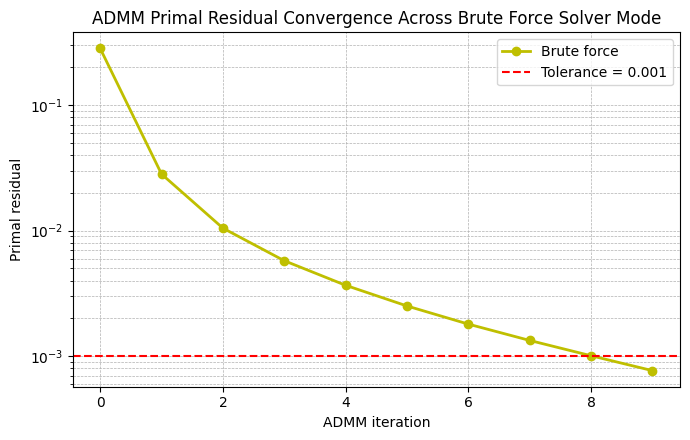

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

results = {
    "Brute force": result_bf,
}

plt.figure(figsize=(7, 4.5))

for label, res in results.items():
    hist = pd.DataFrame(res["history"])
    plt.semilogy(
        hist["iter"],
        hist["primal_norm"],
        marker="o",
        color="y",
        linewidth=2,
        label=label,
    )

tol = list(results.values())[0].get("admm_settings", {}).get("primal_tol", 1e-3)
plt.axhline(tol, linestyle="--", linewidth=1.5, label=f"Tolerance = {tol:g}", color="r")

plt.xlabel("ADMM iteration")
plt.ylabel("Primal residual")
plt.title("ADMM Primal Residual Convergence Across Brute Force Solver Mode")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.legend()
plt.tight_layout()

plt.savefig("primal_residual_bf_mode.png", dpi=300, bbox_inches="tight")
plt.show()

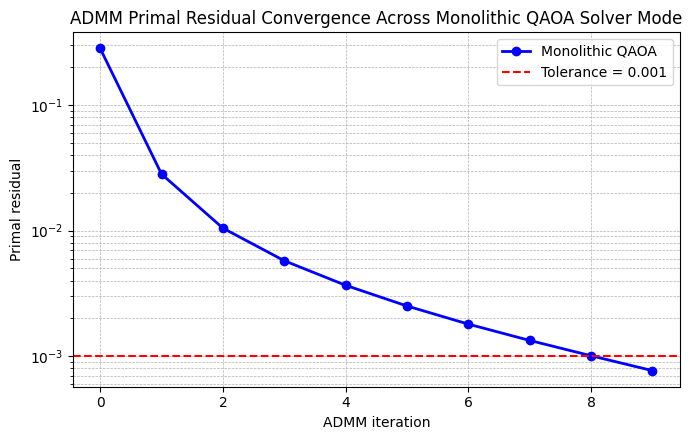

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

results = {
    "Monolithic QAOA": result_mono,
}

plt.figure(figsize=(7, 4.5))

for label, res in results.items():
    hist = pd.DataFrame(res["history"])
    plt.semilogy(
        hist["iter"],
        hist["primal_norm"],
        marker="o",
        color="b",
        linewidth=2,
        label=label,
    )

tol = list(results.values())[0].get("admm_settings", {}).get("primal_tol", 1e-3)
plt.axhline(tol, linestyle="--", linewidth=1.5, label=f"Tolerance = {tol:g}", color="r")

plt.xlabel("ADMM iteration")
plt.ylabel("Primal residual")
plt.title("ADMM Primal Residual Convergence Across Monolithic QAOA Solver Mode")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.legend()
plt.tight_layout()

plt.savefig("primal_residual_mono_mode.png", dpi=300, bbox_inches="tight")
plt.show()

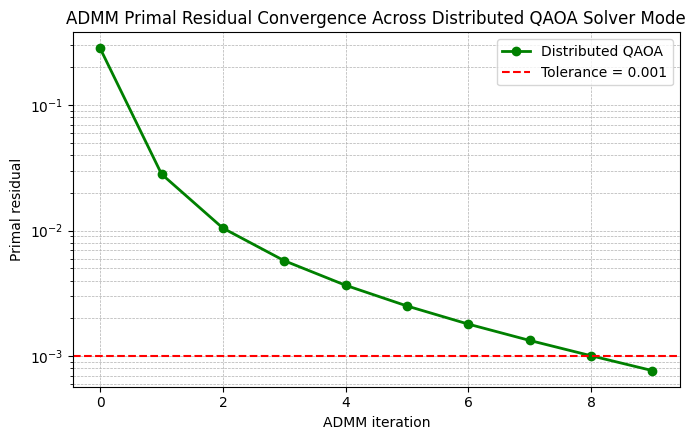

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

results = {
    "Distributed QAOA": result_dist,
}

plt.figure(figsize=(7, 4.5))

for label, res in results.items():
    hist = pd.DataFrame(res["history"])
    plt.semilogy(
        hist["iter"],
        hist["primal_norm"],
        marker="o",
        color="g",
        linewidth=2,
        label=label,
    )

tol = list(results.values())[0].get("admm_settings", {}).get("primal_tol", 1e-3)
plt.axhline(tol, linestyle="--", linewidth=1.5, label=f"Tolerance = {tol:g}", color="r")

plt.xlabel("ADMM iteration")
plt.ylabel("Primal residual")
plt.title("ADMM Primal Residual Convergence Across Distributed QAOA Solver Mode")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.legend()
plt.tight_layout()

plt.savefig("primal_residual_dist_mode.png", dpi=300, bbox_inches="tight")
plt.show()

,Mode,Best bitstring,Best cost
0,Brute force,001000100101111,12678.45
1,Monolithic QAOA,001000100101111,12678.45
2,Distributed QAOA,001000100101111,12678.45


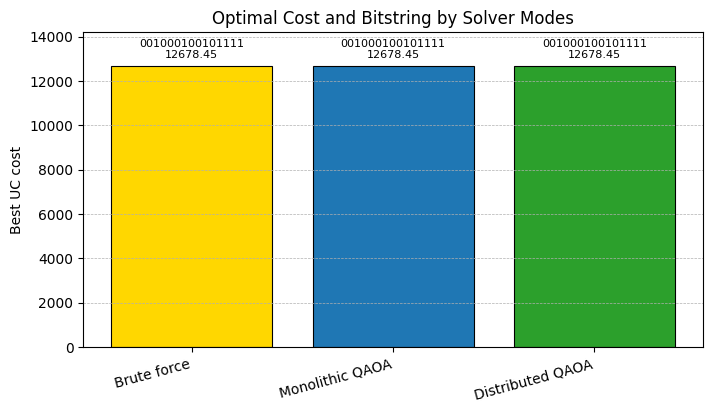

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

results = {
    "Brute force": result_bf,
    "Monolithic QAOA": result_mono,
    "Distributed QAOA": result_dist,
}

rows = []

for mode, res in results.items():
    final = res["final"]
    z = np.asarray(final["z"], dtype=int)

    bitstring = "".join(str(v) for v in z.reshape(-1))
    cost = float(final["cost"])

    rows.append({
        "Mode": mode,
        "Best bitstring": bitstring,
        "Best cost": cost,
    })

summary_df = pd.DataFrame(rows)
display(summary_df)

colors = {
    "Brute force": "gold",
    "Monolithic QAOA": "tab:blue",
    "Distributed QAOA": "tab:green",
}

bar_colors = [colors[m] for m in summary_df["Mode"]]

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(summary_df))
costs = summary_df["Best cost"].to_numpy(dtype=float)

bars = ax.bar(
    x,
    costs,
    color=bar_colors,
    edgecolor="black",
    linewidth=0.8
)

ax.set_xticks(x)
ax.set_xticklabels(summary_df["Mode"], rotation=15, ha="right")
ax.set_ylabel("Best UC cost")
ax.set_title("Optimal Cost and Bitstring by Solver Modes")
ax.grid(axis="y", linestyle="--", linewidth=0.5)

# Make enough vertical space above bars
ymin = 0
ymax = max(costs) * 1.12
ax.set_ylim(ymin, ymax)

# Add labels safely
for i, row in summary_df.iterrows():
    ax.text(
        i,
        row["Best cost"] + 0.02 * max(costs),
        f'{row["Best bitstring"]}\n{row["Best cost"]:.2f}',
        ha="center",
        va="bottom",
        fontsize=8,
        clip_on=True
    )

fig.subplots_adjust(bottom=0.22, top=0.85)

# Do NOT use bbox_inches="tight" here
fig.savefig("best_cost_bitstring_by_all_modes.png", dpi=300)
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

hist = pd.DataFrame(result["history"])
tol = result.get("admm_settings", {}).get("primal_tol", 1e-3)
mode = result.get("binary_solver_mode", "mode")

plt.figure(figsize=(6.5, 4))
plt.semilogy(hist["iter"], hist["primal_norm"], marker="o", linewidth=2)
plt.axhline(tol, linestyle="--", linewidth=1.5, label=f"Tolerance = {tol:g}")

plt.xlabel("ADMM iteration")
plt.ylabel("Primal residual")
plt.title(f"ADMM Primal Residual Convergence ({mode})")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.legend()
plt.tight_layout()

plt.savefig(f"primal_residual_{mode}.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:

# =============================================================================
# Optional: run all three modes and compare final reported solutions
# =============================================================================

modes_to_run = ["bruteforce", "monolithic_qaoa", "telegate_explicit_qaoa"]
results_by_mode = {}

for mode in modes_to_run:
    print("\n\n" + "=" * 90)
    print("Running mode:", mode)
    print("=" * 90)

    binary_cfg.mode = mode

    res = run_uc_3block_admm(
        data=data,
        admm_cfg=admm_cfg,
        solver_cfg=binary_cfg,
        initialization="greedy_marginal_cost",
    )

    results_by_mode[mode] = res
    print_uc_admm_summary(res)

summary_rows = []
exact_cost = solve_exact_simplified_uc(data)["cost"]

for mode, res in results_by_mode.items():
    final = res["final"]
    summary_rows.append(
        {
            "mode": mode,
            "final_cost": final["cost"],
            "gap_to_exact": final["cost"] - exact_cost,
            "relative_gap_percent": 100.0 * (final["cost"] - exact_cost) / abs(exact_cost),
            "best_iter": final["best_iter"],
            "final_z": final["z"],
        }
    )

pd.DataFrame(summary_rows)
